# 🧠 SynthRAD2023: Model 3 — Standard Conditional DDPM (From Scratch)
## Brain MRI-to-Synthetic CT Synthesis via Conditional Denoising Diffusion Probabilistic Model
### Baseline Denoising Diffusion Probabilistic Model Built from Random Initialization

This notebook implements **Model 3: Standard Conditional Denoising Diffusion Probabilistic Model (cDDPM)** from scratch for synthetic CT (sCT) generation from brain MRI on the **SynthRAD2023 Task 1 Brain cohort (UMC Utrecht)**.

---

### 🔬 Research Protocol & Experimental Design:
- **Clean Random Initialization:** Starts entirely from fresh random weights. Zero reliance on, loading of, or searching for previous checkpoints or pretrained weights.
- **Fixed 60-Patient Custom Cohort:** Evaluates the project's fixed 60-patient split (48 Train, 6 Val, 6 Test) locked to `SEED = 42`.
  *(Note: This is a 2D PNG-based adaptation with a custom patient split, not the official 3D SynthRAD challenge split or evaluation pipeline).*
- **Strict Patient-Level Isolation:** Zero slice leakage across partitions. Held-out test patients are strictly frozen and never accessed during training, validation, diagnostics, or checkpoint selection.
- **Standard Baseline Formulation:** Pure $\epsilon$-prediction objective under mean squared error ($L_2$) noise prediction. No auxiliary pixel $L_1$, SSIM, perceptual, or bone losses.
- **Audited Architecture:** Standard compact residual U-Net denoiser with strided-convolution downsampling, sinusoidal time embeddings, and GroupNorm.
- **Mathematically Consistent Sampler:** Deterministic DDIM ($\eta = 0$) reverse diffusion with collinear noise direction update when predicted $x_0$ is clamped.
- **Isolated Workspace:** All artifacts, configurations, checkpoints, logs, and figures are isolated under `/kaggle/working/synthrad_model3_cddpm_from_scratch/`.


In [1]:
# =====================================================================
# CELL 1: ENVIRONMENT SETUP, HARDWARE INSPECTION & DETERMINISTIC SEEDING
# =====================================================================

import os
import sys
import glob
import math
import time
import json
import shutil
import random
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import cv2

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.transforms.functional as TF
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm
from skimage.metrics import structural_similarity as compute_ssim
from skimage.metrics import peak_signal_noise_ratio as compute_psnr
from scipy.spatial.distance import directed_hausdorff

# 1. Device and Hardware Inspection
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("=" * 80)
print(" SYNTHRAD2023 MODEL 3: CONDITIONAL DDPM FROM SCRATCH ")
print("=" * 80)
print(f"PyTorch Version  : {torch.__version__}")
print(f"Compute Device   : {device}")
if torch.cuda.is_available():
    print(f"GPU Model        : {torch.cuda.get_device_name(0)}")
    vram_gb = torch.cuda.get_device_properties(0).total_memory / (1024 ** 3)
    print(f"Total VRAM       : {vram_gb:.2f} GB")
    torch.backends.cudnn.benchmark = True
else:
    print("WARNING: CUDA not available. Running on CPU (training will be slow).")

# 2. Strict Deterministic Random Seeding (Seed 42)
SEED = 42
def seed_everything(seed=42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything(SEED)
print(f"[OK] Deterministic random seed locked to SEED = {SEED}.")

# 3. Output Directory Hierarchy
BASE_OUT_DIR = "/kaggle/working/synthrad_model3_cddpm_from_scratch" if os.path.exists("/kaggle") else "./synthrad_model3_cddpm_from_scratch"
DIR_CONFIGS     = os.path.join(BASE_OUT_DIR, "configs")
DIR_CHECKPOINTS = os.path.join(BASE_OUT_DIR, "checkpoints")
DIR_METRICS     = os.path.join(BASE_OUT_DIR, "metrics")
DIR_FIGURES     = os.path.join(BASE_OUT_DIR, "figures")
DIR_PREDICTIONS = os.path.join(BASE_OUT_DIR, "predictions")
DIR_LOGS        = os.path.join(BASE_OUT_DIR, "logs")
DIR_REPORTS     = os.path.join(BASE_OUT_DIR, "reports")

for d in [DIR_CONFIGS, DIR_CHECKPOINTS, DIR_METRICS, DIR_FIGURES, DIR_PREDICTIONS, DIR_LOGS, DIR_REPORTS]:
    os.makedirs(d, exist_ok=True)

print(f"[OK] Isolated output hierarchy created at: {BASE_OUT_DIR}")
print("=" * 80)


 SYNTHRAD2023 MODEL 3: CONDITIONAL DDPM FROM SCRATCH 
PyTorch Version  : 2.11.0+cu128
Compute Device   : cuda
GPU Model        : Tesla T4
Total VRAM       : 14.56 GB
[OK] Deterministic random seed locked to SEED = 42.
[OK] Isolated output hierarchy created at: /kaggle/working/synthrad_model3_cddpm_from_scratch


In [2]:
# =====================================================================
# CELL 2: REPRODUCIBLE EXPERIMENT CONFIGURATION & METADATA EXPORT
# =====================================================================

CONFIG = {
    "project_name": "SynthRAD2023 Brain MRI-to-CT Synthesis",
    "experiment_name": "Model 3: Standard Conditional DDPM (From Scratch)",
    "cohort": "Task 1 Brain (UMC Utrecht cohort, 60 patients)",
    "base_output_dir": BASE_OUT_DIR,
    "dataset": {
        "candidate_paths": [
            "/kaggle/input/datasets/lohithkgowda/synthrad2023-brain-2d-png/synthrad_png",
            "/kaggle/input/synthrad2023-brain-2d-png/synthrad_png",
            "./synthrad_png",
            "../synthrad_png",
            "synthrad_experiments/baselines/resunet/data"
        ],
        "image_size": 128,
        "input_channels": 3,
        "output_channels": 1,
        "intensity_range": [-1.0, 1.0],
        "exterior_background_fill": -1.0,
        "mask_source": "Strictly MRI-derived (threshold > 15, 7x7 ellipse closing, filled largest contour)",
        "num_workers": 0
    },
    "patient_splits": {
        "seed": 42,
        "isolation_policy": "Strict Patient-Level Isolation (Zero Slices Leakage)",
        "train_patients_count": 48,
        "val_patients_count": 6,
        "test_patients_count": 6,
        "train_expected_slices": 2879,
        "val_expected_slices": 372,
        "test_expected_slices": 363,
        "total_expected_slices": 3614
    },
    "model_architecture": {
        "model_type": "Standard Residual Conditional U-Net Denoiser",
        "in_channels": 3,
        "out_channels": 1,
        "base_channels": 32,
        "channel_multipliers": [1, 2, 4, 8],
        "time_emb_dim": 64,
        "normalization": "GroupNorm (8 groups)",
        "activation": "SiLU",
        "downsampling": "Strided Conv2d (stride=2, padding=1)",
        "upsampling": "ConvTranspose2d (stride=2)",
        "residual_connections": True,
        "attention_modules": False
    },
    "diffusion": {
        "timesteps": 1000,
        "beta_start": 0.0001,
        "beta_end": 0.02,
        "beta_schedule": "linear",
        "prediction_type": "epsilon",
        "ddim_inference_steps": 50,
        "ddim_eta": 0.0
    },
    "training": {
        "epochs": 80,
        "batch_size": 8,
        "learning_rate": 0.0001,
        "weight_decay": 0.0001,
        "optimizer": "AdamW",
        "lr_scheduler": "CosineAnnealingLR (eta_min=1e-6)",
        "grad_clip_max_norm": 1.0,
        "loss_function": "MSE(predicted_noise, true_noise)",
        "mixed_precision": True,
        "checkpoint_interval_epochs": 5,
        "validation_synthesis_interval_epochs": 5,
        "checkpoint_selection_criterion": "Lowest Validation Patient-Mean [Masked_MAE_norm + 0.1 * (1 - Masked_SSIM)]"
    },
    "provisional_hu_mapping": {
        "status": "UNVERIFIED_PROVISIONAL",
        "disclaimer": "PNG intensities [0, 255] are normalized to [-1, 1]. Exact physical HU calibration is unverified for this 2D PNG dataset. HU metrics are reported provisionally for comparison purposes only.",
        "assumed_hu_min": -1000.0,
        "assumed_hu_max": 1500.0,
        "assumed_hu_range": 2500.0,
        "bone_threshold_hu": 300.0
    }
}

config_save_path = os.path.join(DIR_CONFIGS, "cddpm_experiment_config.json")
with open(config_save_path, "w", encoding="utf-8") as f:
    json.dump(CONFIG, f, indent=2)

print(f"[OK] Configuration serialized to: {config_save_path}")


[OK] Configuration serialized to: /kaggle/working/synthrad_model3_cddpm_from_scratch/configs/cddpm_experiment_config.json


In [3]:
# =====================================================================
# CELL 3: DATASET DISCOVERY & EXACT PATIENT-LEVEL SPLIT VERIFICATION
# =====================================================================

def locate_dataset_root(candidate_paths):
    for path in candidate_paths:
        if os.path.exists(path) and os.path.isdir(os.path.join(path, "ct")) and os.path.isdir(os.path.join(path, "mri")):
            return os.path.abspath(path)
    for match in glob.glob("/kaggle/input/**/synthrad_png", recursive=True):
        if os.path.isdir(os.path.join(match, "ct")) and os.path.isdir(os.path.join(match, "mri")):
            return os.path.abspath(match)
    return None

DATASET_ROOT = locate_dataset_root(CONFIG["dataset"]["candidate_paths"])
if DATASET_ROOT is None:
    raise FileNotFoundError(
        "Could not locate SynthRAD2023 dataset directory. "
        "Please attach the Kaggle dataset 'lohithkgowda/synthrad2023-brain-2d-png' "
        "or ensure 'synthrad_png' with 'mri' and 'ct' subdirectories is present."
    )

print(f"[OK] SynthRAD2023 Dataset Root: {DATASET_ROOT}")
ct_dir  = os.path.join(DATASET_ROOT, "ct")
mri_dir = os.path.join(DATASET_ROOT, "mri")

all_ct_files  = sorted([f for f in os.listdir(ct_dir) if f.endswith(".png")])
all_mri_files = sorted([f for f in os.listdir(mri_dir) if f.endswith(".png")])

# Exact filename intersection
common_files = sorted(list(set(all_ct_files).intersection(set(all_mri_files))))
assert len(common_files) == len(all_ct_files) == len(all_mri_files), (
    f"Mismatch in filenames: CT ({len(all_ct_files)}), MRI ({len(all_mri_files)}), Common ({len(common_files)})"
)
print(f"[OK] Total paired slices matched: {len(common_files):,}")

# Group slices by patient ID (prefix before first underscore)
patient_to_slices = {}
for fname in common_files:
    pid = fname.split("_")[0]
    patient_to_slices.setdefault(pid, []).append(fname)

total_patients = len(patient_to_slices)
print(f"[OK] Total unique patients identified: {total_patients}")

# Exact Fixed Patient Split Lists (Do not modify or re-randomize)
EXPECTED_TRAIN_PIDS = sorted([
    "1BA001", "1BA005", "1BA012", "1BA014", "1BA022", "1BA032", "1BA040", "1BA058",
    "1BA075", "1BA082", "1BA085", "1BA091", "1BA100", "1BA103", "1BA105", "1BA116",
    "1BA131", "1BA143", "1BA151", "1BA158", "1BA159", "1BA164", "1BA175", "1BA184",
    "1BA185", "1BA189", "1BA201", "1BA206", "1BA220", "1BA222", "1BA227", "1BA239",
    "1BA247", "1BA253", "1BA260", "1BA266", "1BA278", "1BA288", "1BA292", "1BA294",
    "1BA305", "1BA325", "1BA328", "1BA336", "1BA345", "1BA358", "1BA359", "1BA368"
])
EXPECTED_VAL_PIDS = sorted(["1BA076", "1BA111", "1BA125", "1BA141", "1BA300", "1BA379"])
EXPECTED_TEST_PIDS = sorted(["1BA054", "1BA097", "1BA172", "1BA234", "1BA256", "1BA307"])

# Assert exact patient lists match
discovered_pids = set(patient_to_slices.keys())
assert set(EXPECTED_TRAIN_PIDS).issubset(discovered_pids), "Missing expected training patients!"
assert set(EXPECTED_VAL_PIDS).issubset(discovered_pids), "Missing expected validation patients!"
assert set(EXPECTED_TEST_PIDS).issubset(discovered_pids), "Missing expected test patients!"

# Assert mutual exclusivity
assert set(EXPECTED_TRAIN_PIDS).isdisjoint(set(EXPECTED_VAL_PIDS)), "Train and Val patient sets overlap!"
assert set(EXPECTED_TRAIN_PIDS).isdisjoint(set(EXPECTED_TEST_PIDS)), "Train and Test patient sets overlap!"
assert set(EXPECTED_VAL_PIDS).isdisjoint(set(EXPECTED_TEST_PIDS)), "Val and Test patient sets overlap!"

def gather_file_paths(pids):
    mri_paths, ct_paths = [], []
    for pid in pids:
        for sname in sorted(patient_to_slices[pid]):
            mri_paths.append(os.path.join(mri_dir, sname))
            ct_paths.append(os.path.join(ct_dir, sname))
    return mri_paths, ct_paths

train_mri, train_ct = gather_file_paths(EXPECTED_TRAIN_PIDS)
val_mri, val_ct     = gather_file_paths(EXPECTED_VAL_PIDS)
test_mri, test_ct   = gather_file_paths(EXPECTED_TEST_PIDS)

# Assert exact expected slice counts
print("=" * 80)
print("VERIFYING EXACT FIXED PATIENT SPLIT SLICE COUNTS:")
print(f"  - Training Set   : {len(EXPECTED_TRAIN_PIDS)} patients, {len(train_mri):,} slices (Expected: 2,879)")
print(f"  - Validation Set : {len(EXPECTED_VAL_PIDS)} patients, {len(val_mri):,} slices (Expected: 372)")
print(f"  - Test Set       : {len(EXPECTED_TEST_PIDS)} patients, {len(test_mri):,} slices (Expected: 363)")
print("=" * 80)

assert len(train_mri) == CONFIG["patient_splits"]["train_expected_slices"], (
    f"Train slice count mismatch: found {len(train_mri)}, expected {CONFIG['patient_splits']['train_expected_slices']}"
)
assert len(val_mri) == CONFIG["patient_splits"]["val_expected_slices"], (
    f"Val slice count mismatch: found {len(val_mri)}, expected {CONFIG['patient_splits']['val_expected_slices']}"
)
assert len(test_mri) == CONFIG["patient_splits"]["test_expected_slices"], (
    f"Test slice count mismatch: found {len(test_mri)}, expected {CONFIG['patient_splits']['test_expected_slices']}"
)

print("[PASS] All patient partitions and exact slice counts validated successfully.")

split_info = {
    "train_patients": EXPECTED_TRAIN_PIDS,
    "val_patients": EXPECTED_VAL_PIDS,
    "test_patients": EXPECTED_TEST_PIDS,
    "train_slices_count": len(train_mri),
    "val_slices_count": len(val_mri),
    "test_slices_count": len(test_mri)
}
with open(os.path.join(DIR_CONFIGS, "patient_split.json"), "w", encoding="utf-8") as f:
    json.dump(split_info, f, indent=2)


[OK] SynthRAD2023 Dataset Root: /kaggle/input/datasets/lohithkgowda/synthrad2023-brain-2d-png/synthrad_png
[OK] Total paired slices matched: 3,614
[OK] Total unique patients identified: 60
VERIFYING EXACT FIXED PATIENT SPLIT SLICE COUNTS:
  - Training Set   : 48 patients, 2,879 slices (Expected: 2,879)
  - Validation Set : 6 patients, 372 slices (Expected: 372)
  - Test Set       : 6 patients, 363 slices (Expected: 363)
[PASS] All patient partitions and exact slice counts validated successfully.


In [4]:
# =====================================================================
# CELL 4: REPRODUCIBLE PREPROCESSING PIPELINE & DATASET CLASSES
# =====================================================================

def derive_mri_body_mask(img_arr, threshold=15.0):
    """
    Derives anatomical head contour mask STRICTLY from MRI.
    - Zero ground-truth CT information is used.
    - Threshold grayscale MRI > 15.0.
    - Morphological closing with a 7x7 elliptical structuring element.
    - Retains and fills the largest external contour.
    """
    binary = (img_arr > threshold).astype(np.uint8) * 255
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))
    closed = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, kernel)
    contours, _ = cv2.findContours(closed, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    mask = np.zeros_like(img_arr, dtype=np.uint8)
    if contours:
        largest_contour = max(contours, key=cv2.contourArea)
        cv2.drawContours(mask, [largest_contour], -1, 255, thickness=cv2.FILLED)
    else:
        mask = closed
    return (mask > 0).astype(np.float32)

class SynthRADDiffusionDataset(Dataset):
    """
    Paired Medical Dataset for Conditional Diffusion.
    Outputs:
      - mri: [1, H, W] in [-1.0, 1.0]
      - ct : [1, H, W] in [-1.0, 1.0] (Target state x_0)
      - mask: [1, H, W] binary {0.0, 1.0} derived exclusively from MRI
    """
    def __init__(self, mri_paths, ct_paths, image_size=128, is_train=False):
        assert len(mri_paths) == len(ct_paths), "Mismatch between MRI and CT paths count"
        self.mri_paths  = mri_paths
        self.ct_paths   = ct_paths
        self.image_size = image_size
        self.is_train   = is_train

    def __len__(self):
        return len(self.mri_paths)

    def _process_slice(self, mri_path, ct_path):
        mri_img = Image.open(mri_path).convert('L')
        ct_img  = Image.open(ct_path).convert('L')
        
        mri_arr = np.array(mri_img, dtype=np.float32)
        ct_arr  = np.array(ct_img,  dtype=np.float32)
        
        # Anatomical mask derived exclusively from MRI (zero CT information leakage)
        mri_mask = derive_mri_body_mask(mri_arr)
        mri_arr  = mri_arr * mri_mask
        
        # Bilinear interpolation for images, nearest-neighbor for mask
        mri_res  = cv2.resize(mri_arr,  (self.image_size, self.image_size), interpolation=cv2.INTER_LINEAR)
        ct_res   = cv2.resize(ct_arr,   (self.image_size, self.image_size), interpolation=cv2.INTER_LINEAR)
        mask_res = cv2.resize(mri_mask, (self.image_size, self.image_size), interpolation=cv2.INTER_NEAREST)
        
        # Normalize: [0, 255] -> [-1.0, 1.0]
        mri_norm = (mri_res / 255.0) * 2.0 - 1.0
        ct_norm  = (ct_res  / 255.0) * 2.0 - 1.0
        
        # Strictly set exterior background to -1.0
        mri_norm[mask_res < 0.5] = -1.0
        ct_norm[mask_res < 0.5]  = -1.0
        
        t_mri  = torch.from_numpy(mri_norm).unsqueeze(0).float()
        t_ct   = torch.from_numpy(ct_norm).unsqueeze(0).float()
        t_mask = torch.from_numpy(mask_res).unsqueeze(0).float()
        
        return t_mri, t_ct, t_mask

    def __getitem__(self, idx):
        mri, ct, mask = self._process_slice(self.mri_paths[idx], self.ct_paths[idx])
        
        if self.is_train:
            # Synchronous horizontal flip
            if random.random() > 0.5:
                mri  = TF.hflip(mri)
                ct   = TF.hflip(ct)
                mask = TF.hflip(mask)
            # Synchronous mild affine transform
            angle = random.uniform(-6.0, 6.0)
            tx = int(random.uniform(-3, 3))
            ty = int(random.uniform(-3, 3))
            scale = random.uniform(0.97, 1.03)
            mri  = TF.affine(mri,  angle=angle, translate=[tx, ty], scale=scale, shear=0, fill=-1.0)
            ct   = TF.affine(ct,   angle=angle, translate=[tx, ty], scale=scale, shear=0, fill=-1.0)
            mask = TF.affine(mask, angle=angle, translate=[tx, ty], scale=scale, shear=0, fill=0.0)

        pid   = os.path.basename(self.mri_paths[idx]).split("_")[0]
        sname = os.path.basename(self.mri_paths[idx])

        return {
            "mri": mri,
            "ct":  ct,
            "mask": mask,
            "patient_id": pid,
            "slice_name": sname
        }

# Construct Datasets
BATCH_SIZE = CONFIG["training"]["batch_size"]
IMG_SIZE   = CONFIG["dataset"]["image_size"]
NUM_WORKERS = CONFIG["dataset"]["num_workers"] # Set to 0 to prevent Kaggle multiprocessing cleanup warnings

train_dataset_augmented   = SynthRADDiffusionDataset(train_mri, train_ct, image_size=IMG_SIZE, is_train=True)
train_dataset_eval_frozen = SynthRADDiffusionDataset(train_mri, train_ct, image_size=IMG_SIZE, is_train=False)
val_dataset_eval          = SynthRADDiffusionDataset(val_mri,   val_ct,   image_size=IMG_SIZE, is_train=False)
test_dataset_eval         = SynthRADDiffusionDataset(test_mri,  test_ct,  image_size=IMG_SIZE, is_train=False)

train_loader      = DataLoader(train_dataset_augmented,   batch_size=BATCH_SIZE, shuffle=True,  num_workers=NUM_WORKERS, pin_memory=True)
train_eval_loader = DataLoader(train_dataset_eval_frozen, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)
val_loader        = DataLoader(val_dataset_eval,          batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)

# Dataset Sanity Checks
sample_check = train_dataset_eval_frozen[0]
assert sample_check["mri"].shape == (1, IMG_SIZE, IMG_SIZE), f"Bad MRI shape: {sample_check['mri'].shape}"
assert sample_check["ct"].shape  == (1, IMG_SIZE, IMG_SIZE), f"Bad CT shape: {sample_check['ct'].shape}"
assert sample_check["mask"].shape == (1, IMG_SIZE, IMG_SIZE), f"Bad mask shape: {sample_check['mask'].shape}"
assert torch.isfinite(sample_check["mri"]).all(), "Non-finite values in MRI"
assert torch.isfinite(sample_check["ct"]).all(), "Non-finite values in CT"
assert ((sample_check["mask"] == 0.0) | (sample_check["mask"] == 1.0)).all(), "Mask is not strictly binary"
assert sample_check["mri"].min() >= -1.0 and sample_check["mri"].max() <= 1.0, "MRI out of range [-1, 1]"
assert sample_check["ct"].min() >= -1.0 and sample_check["ct"].max() <= 1.0, "CT out of range [-1, 1]"

print("[PASS] Dataset sanity checks passed:")
print(f"       Train Loader (Augmented)   : {len(train_loader)} batches ({len(train_dataset_augmented)} slices)")
print(f"       Val Loader (Frozen)        : {len(val_loader)} batches ({len(val_dataset_eval)} slices)")
print(f"       Test Slices Ready (Frozen) : {len(test_dataset_eval)} slices (Evaluation gated in final cell)")


[PASS] Dataset sanity checks passed:
       Train Loader (Augmented)   : 360 batches (2879 slices)
       Val Loader (Frozen)        : 47 batches (372 slices)
       Test Slices Ready (Frozen) : 363 slices (Evaluation gated in final cell)


In [5]:
# =====================================================================
# CELL 5: FRESH STANDARD CONDITIONAL U-NET DENOISER ARCHITECTURE
# =====================================================================

class SinusoidalPositionEmbeddings(nn.Module):
    """Standard sinusoidal timestep embeddings."""
    def __init__(self, dim):
        super().__init__()
        self.dim = dim

    def forward(self, time):
        device = time.device
        half_dim = self.dim // 2
        embeddings = math.log(10000.0) / (half_dim - 1)
        embeddings = torch.exp(torch.arange(half_dim, device=device) * -embeddings)
        embeddings = time[:, None] * embeddings[None, :]
        return torch.cat((embeddings.sin(), embeddings.cos()), dim=-1)

class ResidualConvBlock(nn.Module):
    """
    Standard Diffusion Residual Block with GroupNorm, SiLU, and time injection.
    Maintains identity residual connection: h = conv2(act(conv1(x) + time_emb)) + shortcut(x).
    """
    def __init__(self, in_ch, out_ch, time_emb_dim):
        super().__init__()
        self.time_mlp = nn.Linear(time_emb_dim, out_ch)
        self.conv1 = nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1)
        self.gn1   = nn.GroupNorm(8 if out_ch % 8 == 0 else 4, out_ch)
        self.act1  = nn.SiLU()
        self.conv2 = nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1)
        self.gn2   = nn.GroupNorm(8 if out_ch % 8 == 0 else 4, out_ch)
        self.act2  = nn.SiLU()
        self.shortcut = nn.Conv2d(in_ch, out_ch, kernel_size=1) if in_ch != out_ch else nn.Identity()

    def forward(self, x, t_emb):
        h = self.act1(self.gn1(self.conv1(x)))
        h = h + self.act1(self.time_mlp(t_emb))[:, :, None, None]
        h = self.act2(self.gn2(self.conv2(h)))
        return h + self.shortcut(x)

class StandardConditionalUNet(nn.Module):
    """
    Standard Conditional U-Net Denoiser for Model 3.
    - Input: [x_t, MRI, mask] (3 channels).
    - Output: Predicted Gaussian noise epsilon [1 channel], unconstrained (no sigmoid/tanh).
    - Downsampling: Strided Convolutions (kernel=3, stride=2, padding=1).
    - Upsampling: ConvTranspose2d (kernel=2, stride=2).
    - Skip connections: Direct concatenation between encoder and decoder stages.
    - Parameters: ~3.46M (compact, clean standard diffusion baseline).
    """
    def __init__(self, in_channels=3, out_channels=1, base_channels=32, time_emb_dim=64):
        super().__init__()
        self.in_channels = in_channels
        self.out_channels = out_channels
        self.base_channels = base_channels
        self.time_emb_dim = time_emb_dim

        self.time_mlp = nn.Sequential(
            SinusoidalPositionEmbeddings(time_emb_dim),
            nn.Linear(time_emb_dim, time_emb_dim),
            nn.SiLU()
        )
        c = base_channels

        # Encoder stages
        self.enc1  = ResidualConvBlock(in_channels, c, time_emb_dim)            # 128 -> 128
        self.down1 = nn.Conv2d(c, c, kernel_size=3, stride=2, padding=1)        # 128 -> 64
        self.enc2  = ResidualConvBlock(c, c * 2, time_emb_dim)                  # 64  -> 64
        self.down2 = nn.Conv2d(c * 2, c * 2, kernel_size=3, stride=2, padding=1)# 64  -> 32
        self.enc3  = ResidualConvBlock(c * 2, c * 4, time_emb_dim)              # 32  -> 32
        self.down3 = nn.Conv2d(c * 4, c * 4, kernel_size=3, stride=2, padding=1)# 32  -> 16

        # Bottleneck stages
        self.bot1  = ResidualConvBlock(c * 4, c * 8, time_emb_dim)              # 16  -> 16
        self.bot2  = ResidualConvBlock(c * 8, c * 8, time_emb_dim)              # 16  -> 16

        # Decoder stages with skip connections
        self.up3   = nn.ConvTranspose2d(c * 8, c * 4, kernel_size=2, stride=2)  # 16  -> 32
        self.dec3  = ResidualConvBlock(c * 4 + c * 4, c * 4, time_emb_dim)      # cat with enc3
        self.up2   = nn.ConvTranspose2d(c * 4, c * 2, kernel_size=2, stride=2)  # 32  -> 64
        self.dec2  = ResidualConvBlock(c * 2 + c * 2, c * 2, time_emb_dim)      # cat with enc2
        self.up1   = nn.ConvTranspose2d(c * 2, c, kernel_size=2, stride=2)      # 64  -> 128
        self.dec1  = ResidualConvBlock(c + c, c, time_emb_dim)                  # cat with enc1

        # Final projection: 1 unconstrained channel
        self.final_conv = nn.Conv2d(c, out_channels, kernel_size=1)

    def forward(self, x, t):
        assert x.shape[1] == self.in_channels, f"Expected {self.in_channels} channels, got {x.shape[1]}"
        t_emb = self.time_mlp(t)
        
        # Encoder
        e1 = self.enc1(x, t_emb)
        d1 = self.down1(e1)
        e2 = self.enc2(d1, t_emb)
        d2 = self.down2(e2)
        e3 = self.enc3(d2, t_emb)
        d3 = self.down3(e3)

        # Bottleneck
        b = self.bot2(self.bot1(d3, t_emb), t_emb)

        # Decoder with skip connections
        u3 = self.up3(b)
        assert u3.shape[2:] == e3.shape[2:], f"Shape mismatch at level 3: {u3.shape} vs {e3.shape}"
        d3_out = self.dec3(torch.cat([u3, e3], dim=1), t_emb)

        u2 = self.up2(d3_out)
        assert u2.shape[2:] == e2.shape[2:], f"Shape mismatch at level 2: {u2.shape} vs {e2.shape}"
        d2_out = self.dec2(torch.cat([u2, e2], dim=1), t_emb)

        u1 = self.up1(d2_out)
        assert u1.shape[2:] == e1.shape[2:], f"Shape mismatch at level 1: {u1.shape} vs {e1.shape}"
        d1_out = self.dec1(torch.cat([u1, e1], dim=1), t_emb)

        out = self.final_conv(d1_out)
        assert out.shape[1] == self.out_channels, f"Expected {self.out_channels} channels, got {out.shape[1]}"
        return out

# Instantiate Fresh Model 3 Denoiser from Random Initialization
model3 = StandardConditionalUNet(
    in_channels=CONFIG["model_architecture"]["in_channels"],
    out_channels=CONFIG["model_architecture"]["out_channels"],
    base_channels=CONFIG["model_architecture"]["base_channels"],
    time_emb_dim=CONFIG["model_architecture"]["time_emb_dim"]
).to(device)

total_params = sum(p.numel() for p in model3.parameters() if p.requires_grad)
print("=" * 80)
print(f"FRESH MODEL 3 (CONDITIONAL DDPM) DENOISER INITIALIZED RANDOMLY")
print(f"Trainable Parameters : {total_params:,} (~{total_params/1e6:.2f}M)")
print(f"Base Channels        : {CONFIG['model_architecture']['base_channels']}")
print(f"Input Channels       : {CONFIG['model_architecture']['in_channels']} [x_t, MRI, mask]")
print(f"Output Channels      : {CONFIG['model_architecture']['out_channels']} [epsilon]")
print("=" * 80)


FRESH MODEL 3 (CONDITIONAL DDPM) DENOISER INITIALIZED RANDOMLY
Trainable Parameters : 3,456,737 (~3.46M)
Base Channels        : 32
Input Channels       : 3 [x_t, MRI, mask]
Output Channels      : 1 [epsilon]


In [7]:
# =====================================================================
# CELL 6: MATHEMATICALLY CONSISTENT DIFFUSION SCHEDULER & DDIM SAMPLER
# =====================================================================

class DDPMScheduler:
    """
    Standard DDPM noise scheduler with forward noise injection,
    algebraic true-noise inversion, and deterministic DDIM reverse sampling.
    """
    def __init__(self, timesteps=1000, beta_start=1e-4, beta_end=0.02, device="cuda"):
        self.timesteps = timesteps
        self.device = torch.device(device) if isinstance(device, str) else device
        self.betas = torch.linspace(beta_start, beta_end, timesteps, dtype=torch.float32).to(self.device)
        self.alphas = 1.0 - self.betas
        self.alphas_cumprod = torch.cumprod(self.alphas, dim=0).to(self.device)
        self.alphas_cumprod_prev = F.pad(self.alphas_cumprod[:-1], (1, 0), value=1.0)
        
        # Posterior variance (for ancestral sampling if needed)
        self.posterior_variance = self.betas * (1.0 - self.alphas_cumprod_prev) / (1.0 - self.alphas_cumprod)
        self.posterior_variance_clipped = torch.clamp(self.posterior_variance, min=1e-20)

    def add_noise(self, x_0, t):
        """
        Forward diffusion process:
        q(x_t | x_0) = N(sqrt(alpha_bar_t) * x_0, (1 - alpha_bar_t) * I)
        """
        noise = torch.randn_like(x_0)
        alphas_cp = self.alphas_cumprod.to(x_0.device)
        sqrt_alpha = alphas_cp[t].sqrt().view(-1, 1, 1, 1)
        sqrt_one_minus_alpha = (1.0 - alphas_cp[t]).sqrt().view(-1, 1, 1, 1)
        x_t = sqrt_alpha * x_0 + sqrt_one_minus_alpha * noise
        return x_t, noise

    def reconstruct_x0(self, x_t, noise, t):
        """
        Algebraic clean CT inversion when true noise is provided:
        x_0 = (x_t - sqrt(1 - alpha_bar_t) * noise) / sqrt(alpha_bar_t)
        """
        alphas_cp = self.alphas_cumprod.to(x_t.device)
        sqrt_alpha = alphas_cp[t].sqrt().view(-1, 1, 1, 1)
        sqrt_one_minus_alpha = (1.0 - alphas_cp[t]).sqrt().view(-1, 1, 1, 1)
        return (x_t - sqrt_one_minus_alpha * noise) / (sqrt_alpha + 1e-8)

    @torch.no_grad()
    def sample_ddim(self, model, mri_condition, mask_condition, ddim_steps=50, initial_noise=None, instrument=False):
        """
        Deterministic DDIM Reverse Diffusion Sampler (Song et al., 2020) with eta=0.
        Maintains trajectory collinearity when predicted x_0 is clamped to [-1, 1].
        """
        model.eval()
        dev = mri_condition.device
        b   = mri_condition.shape[0]

        if initial_noise is not None:
            x_t = initial_noise.to(dev).clone()
        else:
            x_t = torch.randn_like(mri_condition).to(dev)

        # Evenly spaced descending timesteps: [999, ..., 0]
        timesteps = sorted(torch.linspace(0, self.timesteps - 1, ddim_steps).long().tolist(), reverse=True)
        alphas_cp = self.alphas_cumprod.to(dev)
        diagnostics = []

        for i, t_val in enumerate(timesteps):
            t = torch.full((b,), t_val, device=dev, dtype=torch.long)
            
            # Predict noise: model input is [x_t, MRI, mask]
            pred_noise = model(torch.cat([x_t, mri_condition, mask_condition], dim=1), t)

            alpha_cur  = alphas_cp[t_val]
            alpha_prev = alphas_cp[timesteps[i + 1]] if i < len(timesteps) - 1 else torch.tensor(1.0, device=dev)

            # Predict raw x_0 and clamp to valid normalized range [-1.0, 1.0]
            pred_x0_raw = (x_t - (1.0 - alpha_cur).sqrt() * pred_noise) / (alpha_cur.sqrt() + 1e-8)
            pred_x0_clamped = torch.clamp(pred_x0_raw, -1.0, 1.0)

            # Mathematical consistency correction:
            # Re-project effective noise pointing to clamped x_0 to preserve trajectory collinearity
            pred_noise_adj = (x_t - alpha_cur.sqrt() * pred_x0_clamped) / ((1.0 - alpha_cur).sqrt() + 1e-8)

            # Deterministic DDIM step (eta = 0.0)
            dir_xt = (1.0 - alpha_prev).clamp(min=0.0).sqrt() * pred_noise_adj
            x_t = alpha_prev.sqrt() * pred_x0_clamped + dir_xt

            if instrument and (i % max(1, ddim_steps // 5) == 0 or i == len(timesteps) - 1):
                outside_pct = ((pred_x0_raw < -1.0) | (pred_x0_raw > 1.0)).float().mean().item() * 100.0
                diagnostics.append({
                    "step": i,
                    "timestep": t_val,
                    "latent_mean": x_t.mean().item(),
                    "latent_std": x_t.std().item(),
                    "pred_noise_mean": pred_noise.mean().item(),
                    "pred_noise_std": pred_noise.std().item(),
                    "raw_x0_mean": pred_x0_raw.mean().item(),
                    "raw_x0_std": pred_x0_raw.std().item(),
                    "x0_outside_pct": outside_pct
                })

        # Set scanner air exterior strictly to -1.0 using the MRI-derived mask
        x_t = torch.where(mask_condition > 0.5, x_t, torch.full_like(x_t, -1.0))
        final_sct = torch.clamp(x_t, -1.0, 1.0)

        return (final_sct, diagnostics) if instrument else final_sct

scheduler = DDPMScheduler(
    timesteps=CONFIG["diffusion"]["timesteps"],
    beta_start=CONFIG["diffusion"]["beta_start"],
    beta_end=CONFIG["diffusion"]["beta_end"],
    device=device
)

print("[OK] DDPMScheduler and 50-Step Deterministic DDIM Sampler initialized.")


[OK] DDPMScheduler and 50-Step Deterministic DDIM Sampler initialized.


In [8]:
# =====================================================================
# CELL 7: CLINICAL EVALUATION SUITE & METRIC UTILITIES
# =====================================================================

# Provisional HU mapping parameters (clearly documented as uncalibrated provisional values)
PROV_HU_MIN   = CONFIG["provisional_hu_mapping"]["assumed_hu_min"]
PROV_HU_MAX   = CONFIG["provisional_hu_mapping"]["assumed_hu_max"]
PROV_HU_RANGE = CONFIG["provisional_hu_mapping"]["assumed_hu_range"]
PROV_BONE_TH  = CONFIG["provisional_hu_mapping"]["bone_threshold_hu"]

def norm_to_provisional_hu(norm_arr):
    """Converts normalized [-1.0, 1.0] array to provisional Hounsfield Units [-1000, 1500]."""
    unit = np.clip((norm_arr + 1.0) / 2.0, 0.0, 1.0)
    return unit * PROV_HU_RANGE + PROV_HU_MIN

def evaluate_slice(pred_norm, gt_norm, mask_arr=None):
    """
    Computes normalized PNG metrics and provisional HU metrics on a 2D slice.
    Normalized metrics (MAE, SSIM, PSNR) are the primary basis for research evaluation.
    """
    pred_c = np.clip(pred_norm, -1.0, 1.0)
    gt_c   = np.clip(gt_norm,   -1.0, 1.0)

    # 1. Normalized space metrics in [0.0, 1.0]
    pred_u = (pred_c + 1.0) / 2.0
    gt_u   = (gt_c   + 1.0) / 2.0

    mae_norm  = float(np.mean(np.abs(pred_u - gt_u)))
    rmse_norm = float(np.sqrt(np.mean((pred_u - gt_u) ** 2)))
    psnr_norm = float(compute_psnr(gt_u, pred_u, data_range=1.0))
    ssim_val, ssim_map = compute_ssim(gt_u, pred_u, data_range=1.0, full=True)
    global_ssim = float(ssim_val)

    if mask_arr is not None:
        body = mask_arr > 0.5
        if body.sum() > 0:
            masked_mae_norm = float(np.mean(np.abs(pred_u[body] - gt_u[body])))
            masked_ssim     = float(np.mean(ssim_map[body]))
            masked_mse      = float(np.mean((pred_u[body] - gt_u[body]) ** 2))
            masked_psnr     = float(10.0 * np.log10(1.0 / (masked_mse + 1e-8)))
        else:
            masked_mae_norm = mae_norm
            masked_ssim     = global_ssim
            masked_psnr     = psnr_norm
    else:
        body = np.ones_like(pred_norm, dtype=bool)
        masked_mae_norm = mae_norm
        masked_ssim     = global_ssim
        masked_psnr     = psnr_norm

    # 2. Provisional HU metrics (provisional, uncalibrated)
    pred_hu = norm_to_provisional_hu(pred_c)
    gt_hu   = norm_to_provisional_hu(gt_c)

    hu_mae = float(np.mean(np.abs(pred_hu - gt_hu)))
    if mask_arr is not None and body.sum() > 0:
        masked_hu_mae = float(np.mean(np.abs(pred_hu[body] - gt_hu[body])))
    else:
        masked_hu_mae = hu_mae

    # Provisional Bone Dice (>300 HU)
    real_bone = (gt_hu > PROV_BONE_TH) & body
    fake_bone = (pred_hu > PROV_BONE_TH) & body
    intersection = np.sum(real_bone & fake_bone)
    total_area   = np.sum(real_bone) + np.sum(fake_bone)
    provisional_bone_dice = float((2.0 * intersection) / (total_area + 1e-8)) if total_area > 0 else 1.0

    return {
        "MAE_norm": mae_norm,
        "Masked_MAE_norm": masked_mae_norm,
        "PSNR_dB": psnr_norm,
        "Masked_PSNR_dB": masked_psnr,
        "SSIM": global_ssim,
        "Masked_SSIM": masked_ssim,
        "Provisional_HU_MAE": hu_mae,
        "Provisional_Masked_HU_MAE": masked_hu_mae,
        "Provisional_Bone_Dice": provisional_bone_dice
    }

print("[OK] Clinical evaluation suite initialized.")


[OK] Clinical evaluation suite initialized.


In [10]:
# =====================================================================
# CELL 8: DIAGNOSTIC A — MATHEMATICAL PREFLIGHT TESTS
# =====================================================================

print("=" * 80)
print("DIAGNOSTIC A: MATHEMATICAL PREFLIGHT TESTS")
print("=" * 80)

# 1. Schedule buffer checks
assert len(scheduler.betas) == 1000, "Betas length mismatch"
assert abs(scheduler.betas[0].item() - 1e-4) < 1e-6, "Beta start mismatch"
assert abs(scheduler.betas[-1].item() - 0.02) < 1e-5, "Beta end mismatch"
assert (scheduler.alphas_cumprod[:-1] >= scheduler.alphas_cumprod[1:]).all(), "Alpha-cumprod not monotonically decreasing"
print(f"[PASS] Schedule buffers verified (timesteps=1000, beta_start={scheduler.betas[0].item():.1e}, beta_end={scheduler.betas[-1].item():.2f})")

# 2. Algebraic Inversion with True Noise across timesteps
sample_test = train_dataset_eval_frozen[0]
x_0_test = sample_test["ct"].unsqueeze(0).to(device)
timesteps_to_test = [0, 25, 50, 100, 250, 500, 750, 999]

inversion_results = []
print("Testing clean CT reconstruction from x_t given true noise epsilon:")
for t_val in timesteps_to_test:
    t_tens = torch.tensor([t_val], device=device, dtype=torch.long)
    x_t, true_noise = scheduler.add_noise(x_0_test, t_tens)
    recon_x0 = scheduler.reconstruct_x0(x_t, true_noise, t_tens)
    max_err = (recon_x0 - x_0_test).abs().max().item()
    mean_err = (recon_x0 - x_0_test).abs().mean().item()
    inversion_results.append({"t": t_val, "max_abs_err": max_err, "mean_abs_err": mean_err})
    print(f"  t = {t_val:3d} | Max Inversion Error = {max_err:.2e} | Mean Error = {mean_err:.2e}")

df_inv = pd.DataFrame(inversion_results)
assert df_inv["max_abs_err"].max() < 1e-4, f"Algebraic inversion failed with error {df_inv['max_abs_err'].max()}"
print("[PASS] True-noise algebraic inversion verified (< 1e-4 across all timesteps).")

# 3. Model Forward and Gradient Finite Test
dummy_in = torch.randn(2, 3, 128, 128, device=device)
dummy_t  = torch.randint(0, 1000, (2,), device=device)
model3.zero_grad()
dummy_out = model3(dummy_in, dummy_t)

assert dummy_out.shape == (2, 1, 128, 128), f"Unexpected model output shape: {dummy_out.shape}"
assert torch.isfinite(dummy_out).all(), "Non-finite values in model forward output"

dummy_loss = F.mse_loss(dummy_out, torch.randn_like(dummy_out))
dummy_loss.backward()

finite_grads = all(torch.isfinite(p.grad).all() for p in model3.parameters() if p.grad is not None)
assert finite_grads, "Non-finite gradients detected"
model3.zero_grad()
print("[PASS] Model input/output shapes, finite predictions, and finite gradients verified.")
print("=" * 80)


DIAGNOSTIC A: MATHEMATICAL PREFLIGHT TESTS
[PASS] Schedule buffers verified (timesteps=1000, beta_start=1.0e-04, beta_end=0.02)
Testing clean CT reconstruction from x_t given true noise epsilon:
  t =   0 | Max Inversion Error = 1.19e-07 | Mean Error = 1.61e-08
  t =  25 | Max Inversion Error = 1.19e-07 | Mean Error = 2.08e-08
  t =  50 | Max Inversion Error = 1.19e-07 | Mean Error = 2.46e-08
  t = 100 | Max Inversion Error = 1.19e-07 | Mean Error = 1.15e-08
  t = 250 | Max Inversion Error = 1.79e-07 | Mean Error = 2.33e-08
  t = 500 | Max Inversion Error = 4.47e-07 | Mean Error = 7.31e-08
  t = 750 | Max Inversion Error = 2.09e-06 | Mean Error = 3.44e-07
  t = 999 | Max Inversion Error = 1.93e-05 | Mean Error = 3.49e-06
[PASS] True-noise algebraic inversion verified (< 1e-4 across all timesteps).
[PASS] Model input/output shapes, finite predictions, and finite gradients verified.


DIAGNOSTIC B: FIXED-SAMPLE OVERFIT SANITY TEST
Verifying gradient propagation and architecture capacity on 4 fixed training slices
using a standalone temporary model instance.


Overfit Sanity Test:   0%|          | 0/100 [00:00<?, ?it/s]

Step  0 Initial Loss : 1.56096
Step 99 Final Loss   : 0.01264
Loss Reduction Ratio : 0.0081


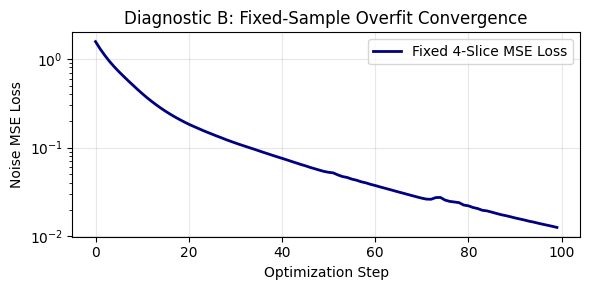

[PASS] Diagnostic B completed. Architecture converges smoothly on fixed target noise.


In [11]:
# =====================================================================
# CELL 9: DIAGNOSTIC B — FIXED-SAMPLE OVERFIT SANITY TEST
# =====================================================================

print("=" * 80)
print("DIAGNOSTIC B: FIXED-SAMPLE OVERFIT SANITY TEST")
print("=" * 80)
print("Verifying gradient propagation and architecture capacity on 4 fixed training slices")
print("using a standalone temporary model instance.")

# Select 4 fixed training slices
seed_everything(SEED)
fixed_indices = [0, 5, 10, 15]
fixed_batch = [train_dataset_eval_frozen[i] for i in fixed_indices]

b_mri  = torch.stack([s["mri"] for s in fixed_batch]).to(device)
b_ct   = torch.stack([s["ct"]  for s in fixed_batch]).to(device)
b_mask = torch.stack([s["mask"] for s in fixed_batch]).to(device)

# Fix timesteps and Gaussian noise
fixed_t = torch.tensor([50, 200, 500, 800], device=device, dtype=torch.long)
fixed_xt, fixed_noise = scheduler.add_noise(b_ct, fixed_t)

# Standalone diagnostic model instance (not modifying main model weights)
diagnostic_model = StandardConditionalUNet(
    in_channels=CONFIG["model_architecture"]["in_channels"],
    out_channels=CONFIG["model_architecture"]["out_channels"],
    base_channels=16, # Compact instance for rapid sanity check
    time_emb_dim=64
).to(device)

diag_opt = torch.optim.AdamW(diagnostic_model.parameters(), lr=5e-4, weight_decay=0.0)

overfit_history = []
pbar_sanity = tqdm(range(100), desc="Overfit Sanity Test")
for step in pbar_sanity:
    diagnostic_model.train()
    diag_opt.zero_grad()
    pred_eps = diagnostic_model(torch.cat([fixed_xt, b_mri, b_mask], dim=1), fixed_t)
    loss = F.mse_loss(pred_eps, fixed_noise)
    loss.backward()
    diag_opt.step()
    
    loss_val = loss.item()
    overfit_history.append(loss_val)
    if step % 20 == 0 or step == 99:
        pbar_sanity.set_postfix({"MSE": f"{loss_val:.5f}"})

print(f"Step  0 Initial Loss : {overfit_history[0]:.5f}")
print(f"Step 99 Final Loss   : {overfit_history[-1]:.5f}")
print(f"Loss Reduction Ratio : {overfit_history[-1] / overfit_history[0]:.4f}")

# Plot overfit curve
plt.figure(figsize=(6, 3), dpi=100)
plt.plot(overfit_history, color="navy", lw=2, label="Fixed 4-Slice MSE Loss")
plt.xlabel("Optimization Step")
plt.ylabel("Noise MSE Loss")
plt.title("Diagnostic B: Fixed-Sample Overfit Convergence")
plt.yscale("log")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(DIR_FIGURES, "diagnostic_b_overfit_sanity.png"))
plt.show()

# Clean up diagnostic model to free memory
del diagnostic_model, diag_opt
if torch.cuda.is_available():
    torch.cuda.empty_cache()

print("[PASS] Diagnostic B completed. Architecture converges smoothly on fixed target noise.")
print("=" * 80)


DIAGNOSTIC C: UNTRAINED SAMPLER SMOKE TEST
Testing DDIM sampler execution on a validation slice with fresh randomly initialized model3.
NOTE: Outputs are labeled explicitly as UNTRAINED outputs (smoke test only).


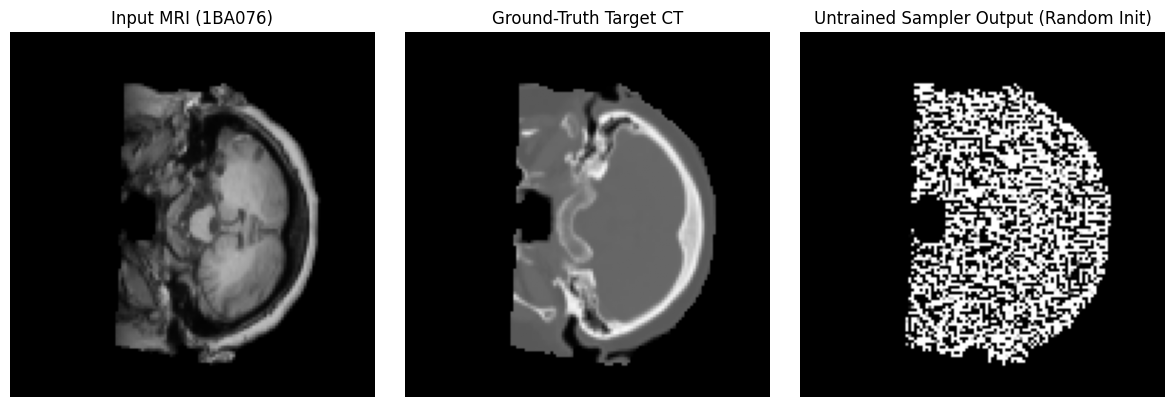

[PASS] DDIM sampler successfully executed 10 reverse steps.
       Latent shape: torch.Size([1, 1, 128, 128]), finite=True


In [12]:
# =====================================================================
# CELL 10: DIAGNOSTIC C — UNTRAINED SAMPLER SMOKE TEST
# =====================================================================

print("=" * 80)
print("DIAGNOSTIC C: UNTRAINED SAMPLER SMOKE TEST")
print("=" * 80)
print("Testing DDIM sampler execution on a validation slice with fresh randomly initialized model3.")
print("NOTE: Outputs are labeled explicitly as UNTRAINED outputs (smoke test only).")

smoke_item = val_dataset_eval[0]
s_mri  = smoke_item["mri"].unsqueeze(0).to(device)
s_ct   = smoke_item["ct"].unsqueeze(0).to(device)
s_mask = smoke_item["mask"].unsqueeze(0).to(device)

# Deterministic initial noise for smoke test
gen_smoke = torch.Generator(device=device)
gen_smoke.manual_seed(SEED)
smoke_init_noise = torch.randn(s_mri.shape, generator=gen_smoke, device=device)

with torch.no_grad():
    untrained_sct, smoke_diag = scheduler.sample_ddim(
        model3, s_mri, s_mask, ddim_steps=10, initial_noise=smoke_init_noise, instrument=True
    )

assert untrained_sct.shape == s_ct.shape, f"Unexpected shape from DDIM sampler: {untrained_sct.shape}"
assert torch.isfinite(untrained_sct).all(), "Non-finite values in sampler output"
assert (untrained_sct >= -1.0).all() and (untrained_sct <= 1.0).all(), "Sampler output outside [-1, 1]"

fig, axes = plt.subplots(1, 3, figsize=(12, 4), dpi=100)
axes[0].imshow(s_mri.squeeze().cpu().numpy(), cmap="gray", vmin=-1.0, vmax=1.0)
axes[0].set_title(f"Input MRI ({smoke_item['patient_id']})")
axes[0].axis("off")

axes[1].imshow(s_ct.squeeze().cpu().numpy(), cmap="gray", vmin=-1.0, vmax=1.0)
axes[1].set_title("Ground-Truth Target CT")
axes[1].axis("off")

axes[2].imshow(untrained_sct.squeeze().cpu().numpy(), cmap="gray", vmin=-1.0, vmax=1.0)
axes[2].set_title("Untrained Sampler Output (Random Init)")
axes[2].axis("off")

plt.tight_layout()
plt.savefig(os.path.join(DIR_FIGURES, "diagnostic_c_untrained_smoke_test.png"))
plt.show()

print(f"[PASS] DDIM sampler successfully executed 10 reverse steps.")
print(f"       Latent shape: {untrained_sct.shape}, finite={torch.isfinite(untrained_sct).all().item()}")
print("=" * 80)


In [13]:
# =====================================================================
# CELL 11: TRAINING & VALIDATION EVALUATION ENGINE
# =====================================================================

def create_deterministic_validation_noise(val_dataset, seed=42):
    """
    Generates fixed, slice-specific initial noise for validation.
    Guarantees that each validation slice receives deterministic, unique initial noise.
    """
    noise_dict = {}
    gen = torch.Generator()
    gen.manual_seed(seed)
    for idx in range(len(val_dataset)):
        noise = torch.randn((1, 1, CONFIG["dataset"]["image_size"], CONFIG["dataset"]["image_size"]), generator=gen)
        noise_dict[idx] = noise
    return noise_dict

FIXED_VAL_NOISE = create_deterministic_validation_noise(val_dataset_eval, seed=SEED)
print(f"[OK] Deterministic validation noise pool created for {len(FIXED_VAL_NOISE)} slices.")

def run_validation_evaluation(model, val_loader, scheduler, ddim_steps=50):
    """
    Runs deterministic DDIM evaluation across the frozen validation split.
    Computes patient-level means as the primary basis for checkpoint selection.
    """
    model.eval()
    slice_records = []
    patient_slices = {}
    
    global_idx = 0
    with torch.no_grad():
        for batch in val_loader:
            mri  = batch["mri"].to(device)
            ct   = batch["ct"].to(device)
            mask = batch["mask"].to(device)
            pids = batch["patient_id"]
            snames = batch["slice_name"]
            b_size = mri.size(0)

            # Gather deterministic slice-specific initial noise
            batch_noise = torch.cat([FIXED_VAL_NOISE[global_idx + i] for i in range(b_size)], dim=0).to(device)
            global_idx += b_size

            # Run deterministic DDIM
            sct = scheduler.sample_ddim(model, mri, mask, ddim_steps=ddim_steps, initial_noise=batch_noise)

            sct_np  = sct.squeeze(1).cpu().numpy()
            ct_np   = ct.squeeze(1).cpu().numpy()
            mask_np = mask.squeeze(1).cpu().numpy()

            for i in range(b_size):
                pid = pids[i]
                res = evaluate_slice(sct_np[i], ct_np[i], mask_np[i])
                res["patient_id"] = pid
                res["slice_name"] = snames[i]
                slice_records.append(res)
                patient_slices.setdefault(pid, []).append(res)

    df_slices = pd.DataFrame(slice_records)

    # Patient-level mean calculation (unbiased patient-level aggregation)
    patient_records = []
    for pid, records in patient_slices.items():
        pdf = pd.DataFrame(records)
        p_dict = {
            "patient_id": pid,
            "Masked_MAE_norm": float(pdf["Masked_MAE_norm"].mean()),
            "Masked_SSIM": float(pdf["Masked_SSIM"].mean()),
            "Masked_PSNR_dB": float(pdf["Masked_PSNR_dB"].mean()),
            "Provisional_Masked_HU_MAE": float(pdf["Provisional_Masked_HU_MAE"].mean())
        }
        patient_records.append(p_dict)

    df_patients = pd.DataFrame(patient_records)

    val_summary = {
        "Patient_Mean_Masked_MAE": float(df_patients["Masked_MAE_norm"].mean()),
        "Patient_Std_Masked_MAE":  float(df_patients["Masked_MAE_norm"].std()),
        "Patient_Mean_Masked_SSIM": float(df_patients["Masked_SSIM"].mean()),
        "Patient_Std_Masked_SSIM":  float(df_patients["Masked_SSIM"].std()),
        "Patient_Mean_Masked_PSNR": float(df_patients["Masked_PSNR_dB"].mean()),
        "Patient_Mean_Provisional_HU_MAE": float(df_patients["Provisional_Masked_HU_MAE"].mean()),
        # Selection criterion: Patient-mean Masked MAE + 0.1 * (1 - Patient-mean Masked SSIM)
        "Composite_Score": float(df_patients["Masked_MAE_norm"].mean() + 0.10 * (1.0 - df_patients["Masked_SSIM"].mean()))
    }

    return val_summary, df_slices, df_patients

print("[OK] Validation evaluation engine initialized.")


[OK] Deterministic validation noise pool created for 372 slices.
[OK] Validation evaluation engine initialized.


In [14]:
# =====================================================================
# CELL 12: FRESH 80-EPOCH cDDPM TRAINING ENGINE
# =====================================================================

EPOCHS = CONFIG["training"]["epochs"]
LR     = CONFIG["training"]["learning_rate"]
WD     = CONFIG["training"]["weight_decay"]
CKPT_INTERVAL = CONFIG["training"]["checkpoint_interval_epochs"]
VAL_SYNTH_INTERVAL = CONFIG["training"]["validation_synthesis_interval_epochs"]

optimizer = torch.optim.AdamW(model3.parameters(), lr=LR, weight_decay=WD)
lr_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-6)
scaler = torch.amp.GradScaler('cuda', enabled=(device.type == "cuda"))

best_val_score = float("inf")
best_epoch = 0

train_history = []
val_history   = []

bins = [(0, 250), (250, 500), (500, 750), (750, 1000)]

start_train_time = time.time()
print("=" * 80)
print(f"STARTING FRESH MODEL 3 (CONDITIONAL DDPM) TRAINING ({EPOCHS} EPOCHS)")
print(f"Random Initialization : Verified")
print(f"Loss Function         : MSE(predicted_noise, true_noise)")
print(f"Optimizer             : AdamW (lr={LR}, weight_decay={WD})")
print(f"Periodic Checkpoints  : Every {CKPT_INTERVAL} Epochs")
print(f"Validation Synthesis  : Every {VAL_SYNTH_INTERVAL} Epochs + Epoch 1 & {EPOCHS}")
print(f"Checkpoint Criterion  : Lowest Patient-Mean [Masked_MAE_norm + 0.1 * (1 - Masked_SSIM)]")
print("=" * 80)

for epoch in range(1, EPOCHS + 1):
    model3.train()
    running_train_loss = 0.0
    
    pbar = tqdm(train_loader, desc=f"Epoch [{epoch:02d}/{EPOCHS}] Train")
    for batch in pbar:
        mri  = batch["mri"].to(device)
        ct   = batch["ct"].to(device)
        mask = batch["mask"].to(device)
        b_sz = ct.shape[0]

        # Sample diffusion timesteps uniformly
        t = torch.randint(0, scheduler.timesteps, (b_sz,), device=device).long()
        x_t, noise = scheduler.add_noise(ct, t)

        optimizer.zero_grad()
        with torch.amp.autocast('cuda', enabled=(device.type == "cuda")):
            pred_noise = model3(torch.cat([x_t, mri, mask], dim=1), t)
            loss = F.mse_loss(pred_noise, noise)

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model3.parameters(), max_norm=CONFIG["training"]["grad_clip_max_norm"])
        scaler.step(optimizer)
        scaler.update()

        running_train_loss += loss.item()
        pbar.set_postfix({"MSE_loss": f"{loss.item():.4f}"})

    lr_scheduler.step()
    cur_lr = optimizer.param_groups[0]["lr"]
    epoch_train_loss = running_train_loss / len(train_loader)

    # Validation Noise-Prediction MSE & Binned Analysis
    model3.eval()
    running_val_mse = 0.0
    running_val_masked_mse = 0.0
    val_bin_losses = {b: [] for b in bins}

    with torch.no_grad():
        for val_batch in val_loader:
            mri_v  = val_batch["mri"].to(device)
            ct_v   = val_batch["ct"].to(device)
            mask_v = val_batch["mask"].to(device)
            b_v    = ct_v.shape[0]

            t_v = torch.randint(0, scheduler.timesteps, (b_v,), device=device).long()
            x_t_v, noise_v = scheduler.add_noise(ct_v, t_v)

            with torch.amp.autocast('cuda', enabled=(device.type == "cuda")):
                pred_noise_v = model3(torch.cat([x_t_v, mri_v, mask_v], dim=1), t_v)
                v_loss = F.mse_loss(pred_noise_v, noise_v)

            running_val_mse += v_loss.item()
            body_v = mask_v > 0.5
            if body_v.sum() > 0:
                running_val_masked_mse += F.mse_loss(pred_noise_v[body_v], noise_v[body_v]).item()

            for (t_low, t_high) in bins:
                mask_bin = (t_v >= t_low) & (t_v < t_high)
                if mask_bin.sum() > 0:
                    val_bin_losses[(t_low, t_high)].append(
                        F.mse_loss(pred_noise_v[mask_bin], noise_v[mask_bin]).item()
                    )

    epoch_val_mse = running_val_mse / len(val_loader)
    epoch_val_masked_mse = running_val_masked_mse / len(val_loader)

    # Periodic Full DDIM Validation Synthesis
    run_synthesis = (epoch % VAL_SYNTH_INTERVAL == 0) or (epoch == 1) or (epoch == EPOCHS)
    val_record = {
        "epoch": epoch,
        "lr": cur_lr,
        "train_mse_loss": epoch_train_loss,
        "val_mse_loss": epoch_val_mse,
        "val_masked_mse_loss": epoch_val_masked_mse,
        "synthesis_evaluated": run_synthesis
    }

    saved_flag = ""
    if run_synthesis:
        print(f"--> Running 50-step DDIM Validation Synthesis for Epoch {epoch}...")
        val_summary, df_sl, df_pt = run_validation_evaluation(
            model3, val_loader, scheduler, ddim_steps=CONFIG["diffusion"]["ddim_inference_steps"]
        )
        val_record.update(val_summary)

        # Checkpoint Selection based on Validation Patient-Mean Composite Score
        if val_summary["Composite_Score"] < best_val_score:
            best_val_score = val_summary["Composite_Score"]
            best_epoch = epoch

            best_ckpt_path = os.path.join(DIR_CHECKPOINTS, "best_model3_cddpm_from_scratch.pth")
            torch.save({
                "epoch": best_epoch,
                "model_state_dict": model3.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "lr_scheduler_state_dict": lr_scheduler.state_dict(),
                "val_score": best_val_score,
                "val_metrics": val_summary,
                "config": CONFIG
            }, best_ckpt_path)

            saved_flag = " ⭐ [BEST CHECKPOINT SAVED]"

        print(f"Epoch [{epoch:02d}/{EPOCHS}] | Train MSE: {epoch_train_loss:.4f} | Val MSE: {epoch_val_mse:.4f} | "
              f"Score: {val_summary['Composite_Score']:.4f} (Masked MAE: {val_summary['Patient_Mean_Masked_MAE']:.4f}, "
              f"Masked SSIM: {val_summary['Patient_Mean_Masked_SSIM']:.4f}, Masked PSNR: {val_summary['Patient_Mean_Masked_PSNR']:.2f} dB){saved_flag}")
    else:
        print(f"Epoch [{epoch:02d}/{EPOCHS}] | Train MSE: {epoch_train_loss:.4f} | Val MSE: {epoch_val_mse:.4f} (LR: {cur_lr:.2e})")

    # Periodic Checkpoints (Every 5 Epochs)
    if epoch % CKPT_INTERVAL == 0:
        periodic_path = os.path.join(DIR_CHECKPOINTS, f"checkpoint_epoch_{epoch:03d}.pth")
        torch.save({
            "epoch": epoch,
            "model_state_dict": model3.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "lr_scheduler_state_dict": lr_scheduler.state_dict(),
            "val_score": val_record.get("Composite_Score", None),
            "val_metrics": val_record,
            "config": CONFIG
        }, periodic_path)
        print(f"  [CKPT] Periodic checkpoint saved: {periodic_path}")

    train_history.append({"epoch": epoch, "lr": cur_lr, "train_mse_loss": epoch_train_loss, "val_mse_loss": epoch_val_mse})
    val_history.append(val_record)

# Save Final Epoch Checkpoint
final_ckpt_path = os.path.join(DIR_CHECKPOINTS, "final_model3_cddpm_from_scratch.pth")
torch.save({
    "epoch": EPOCHS,
    "model_state_dict": model3.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "lr_scheduler_state_dict": lr_scheduler.state_dict(),
    "config": CONFIG
}, final_ckpt_path)

total_train_min = (time.time() - start_train_time) / 60.0

# Export history CSVs
pd.DataFrame(train_history).to_csv(os.path.join(DIR_METRICS, "training_loss_history.csv"), index=False)
pd.DataFrame(val_history).to_csv(os.path.join(DIR_METRICS, "validation_metrics_history.csv"), index=False)

print("=" * 80)
print(f"TRAINING COMPLETED in {total_train_min:.2f} minutes.")
print(f"Best Validation Epoch : {best_epoch} (Score: {best_val_score:.4f})")
print(f"Best Checkpoint File  : {os.path.join(DIR_CHECKPOINTS, 'best_model3_cddpm_from_scratch.pth')}")
print(f"Final Checkpoint File : {final_ckpt_path}")
print("=" * 80)


STARTING FRESH MODEL 3 (CONDITIONAL DDPM) TRAINING (80 EPOCHS)
Random Initialization : Verified
Loss Function         : MSE(predicted_noise, true_noise)
Optimizer             : AdamW (lr=0.0001, weight_decay=0.0001)
Periodic Checkpoints  : Every 5 Epochs
Validation Synthesis  : Every 5 Epochs + Epoch 1 & 80
Checkpoint Criterion  : Lowest Patient-Mean [Masked_MAE_norm + 0.1 * (1 - Masked_SSIM)]


Epoch [01/80] Train:   0%|          | 0/360 [00:00<?, ?it/s]

--> Running 50-step DDIM Validation Synthesis for Epoch 1...
Epoch [01/80] | Train MSE: 0.0696 | Val MSE: 0.0393 | Score: 0.2166 (Masked MAE: 0.1385, Masked SSIM: 0.2196, Masked PSNR: 14.59 dB) ⭐ [BEST CHECKPOINT SAVED]


Epoch [02/80] Train:   0%|          | 0/360 [00:00<?, ?it/s]

Epoch [02/80] | Train MSE: 0.0281 | Val MSE: 0.0205 (LR: 9.98e-05)


...

Epoch [78/80] | Train MSE: 0.0077 | Val MSE: 0.0082 (LR: 1.15e-06)


Epoch [79/80] Train:   0%|          | 0/360 [00:00<?, ?it/s]

Epoch [79/80] | Train MSE: 0.0071 | Val MSE: 0.0096 (LR: 1.04e-06)


Epoch [80/80] Train:   0%|          | 0/360 [00:00<?, ?it/s]

--> Running 50-step DDIM Validation Synthesis for Epoch 80...
Epoch [80/80] | Train MSE: 0.0080 | Val MSE: 0.0068 | Score: 0.0766 (Masked MAE: 0.0590, Masked SSIM: 0.8238, Masked PSNR: 21.18 dB)
  [CKPT] Periodic checkpoint saved: /kaggle/working/synthrad_model3_cddpm_from_scratch/checkpoints/checkpoint_epoch_080.pth
TRAINING COMPLETED in 75.88 minutes.
Best Validation Epoch : 60 (Score: 0.0755)
Best Checkpoint File  : /kaggle/working/synthrad_model3_cddpm_from_scratch/checkpoints/best_model3_cddpm_from_scratch.pth
Final Checkpoint File : /kaggle/working/synthrad_model3_cddpm_from_scratch/checkpoints/final_model3_cddpm_from_scratch.pth


In [15]:
# =====================================================================
# CELL 13: FROZEN BEST-CHECKPOINT EVALUATION (TRAIN & VALIDATION ONLY)
# =====================================================================

best_ckpt_file = os.path.join(DIR_CHECKPOINTS, "best_model3_cddpm_from_scratch.pth")
if not os.path.exists(best_ckpt_file):
    raise FileNotFoundError(f"Best checkpoint not found: {best_ckpt_file}")

ckpt_data = torch.load(best_ckpt_file, map_location=device)
model3.load_state_dict(ckpt_data["model_state_dict"])
model3.eval()

print("=" * 80)
print(f"[OK] Frozen Best Checkpoint loaded from: {best_ckpt_file}")
print(f"     Trained Epoch: {ckpt_data.get('epoch', 'N/A')}")
print(f"     Best Score   : {ckpt_data.get('val_score', 'N/A')}")
print("=" * 80)

def evaluate_full_split(loader, split_name):
    """Evaluates a split and records slice and patient metrics without touching test data."""
    slice_records = []
    patient_slices = {}
    
    with torch.no_grad():
        for batch in tqdm(loader, desc=f"Evaluating {split_name} Split"):
            mri  = batch["mri"].to(device)
            ct   = batch["ct"].to(device)
            mask = batch["mask"].to(device)
            pids = batch["patient_id"]
            snames = batch["slice_name"]
            
            sct = scheduler.sample_ddim(model3, mri, mask, ddim_steps=CONFIG["diffusion"]["ddim_inference_steps"])
            
            sct_np  = sct.squeeze(1).cpu().numpy()
            ct_np   = ct.squeeze(1).cpu().numpy()
            mask_np = mask.squeeze(1).cpu().numpy()
            mri_np  = mri.squeeze(1).cpu().numpy()
            
            for i in range(mri.size(0)):
                pid = pids[i]
                res = evaluate_slice(sct_np[i], ct_np[i], mask_np[i])
                res["patient_id"] = pid
                res["slice_name"] = snames[i]
                res["split"]      = split_name
                slice_records.append(res)
                patient_slices.setdefault(pid, []).append({
                    "res": res, "mri": mri_np[i], "gt": ct_np[i], "sct": sct_np[i], "sname": snames[i]
                })

    df_sl = pd.DataFrame(slice_records)
    
    patient_records = []
    metric_cols = [
        "MAE_norm", "Masked_MAE_norm", "PSNR_dB", "Masked_PSNR_dB",
        "SSIM", "Masked_SSIM", "Provisional_HU_MAE", "Provisional_Masked_HU_MAE", "Provisional_Bone_Dice"
    ]
    for pid in sorted(list(patient_slices.keys())):
        pdf = df_sl[df_sl["patient_id"] == pid]
        p_dict = {"patient_id": pid, "split": split_name, "slice_count": len(pdf)}
        for c in metric_cols:
            p_dict[f"{c}_mean"] = float(pdf[c].mean())
            p_dict[f"{c}_std"]  = float(pdf[c].std())
        patient_records.append(p_dict)
        
    df_pt = pd.DataFrame(patient_records)
    return df_sl, df_pt, patient_slices

# Run evaluation on Validation split
print("Evaluating Frozen Validation Split (6 patients, 372 slices)...")
df_val_slices, df_val_patients, val_vis_dict = evaluate_full_split(val_loader, "Validation")

# Export validation metrics CSVs
df_val_slices.to_csv(os.path.join(DIR_METRICS, "validation_slice_metrics.csv"), index=False)
df_val_patients.to_csv(os.path.join(DIR_METRICS, "validation_patient_metrics.csv"), index=False)

print("")
print("=" * 80)
print("FROZEN VALIDATION RESULTS (PATIENT-LEVEL MEAN ± STD):")
print("=" * 80)
print(f"  Masked MAE (norm)         : {df_val_patients['Masked_MAE_norm_mean'].mean():.4f} ± {df_val_patients['Masked_MAE_norm_mean'].std():.4f}")
print(f"  Masked SSIM               : {df_val_patients['Masked_SSIM_mean'].mean():.4f} ± {df_val_patients['Masked_SSIM_mean'].std():.4f}")
print(f"  Masked PSNR (dB)          : {df_val_patients['Masked_PSNR_dB_mean'].mean():.2f} ± {df_val_patients['Masked_PSNR_dB_mean'].std():.2f}")
print(f"  Global SSIM               : {df_val_patients['SSIM_mean'].mean():.4f} ± {df_val_patients['SSIM_mean'].std():.4f}")
print(f"  Provisional Masked HU-MAE : {df_val_patients['Provisional_Masked_HU_MAE_mean'].mean():.1f} ± {df_val_patients['Provisional_Masked_HU_MAE_mean'].std():.1f} HU")
print("=" * 80)


[OK] Frozen Best Checkpoint loaded from: /kaggle/working/synthrad_model3_cddpm_from_scratch/checkpoints/best_model3_cddpm_from_scratch.pth
     Trained Epoch: 60
     Best Score   : 0.07545658490033587
Evaluating Frozen Validation Split (6 patients, 372 slices)...


Evaluating Validation Split:   0%|          | 0/47 [00:00<?, ?it/s]


FROZEN VALIDATION RESULTS (PATIENT-LEVEL MEAN ± STD):
  Masked MAE (norm)         : 0.0575 ± 0.0046
  Masked SSIM               : 0.8203 ± 0.0271
  Masked PSNR (dB)          : 21.15 ± 0.48
  Global SSIM               : 0.9053 ± 0.0075
  Provisional Masked HU-MAE : 143.6 ± 11.5 HU


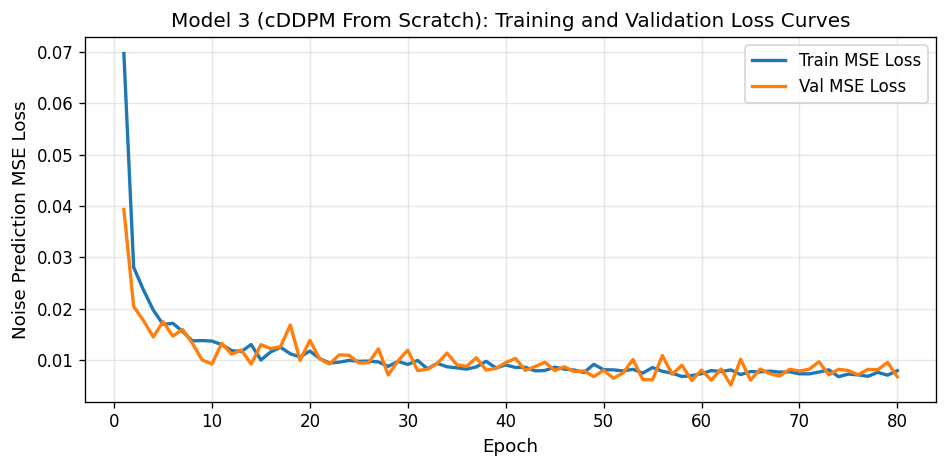

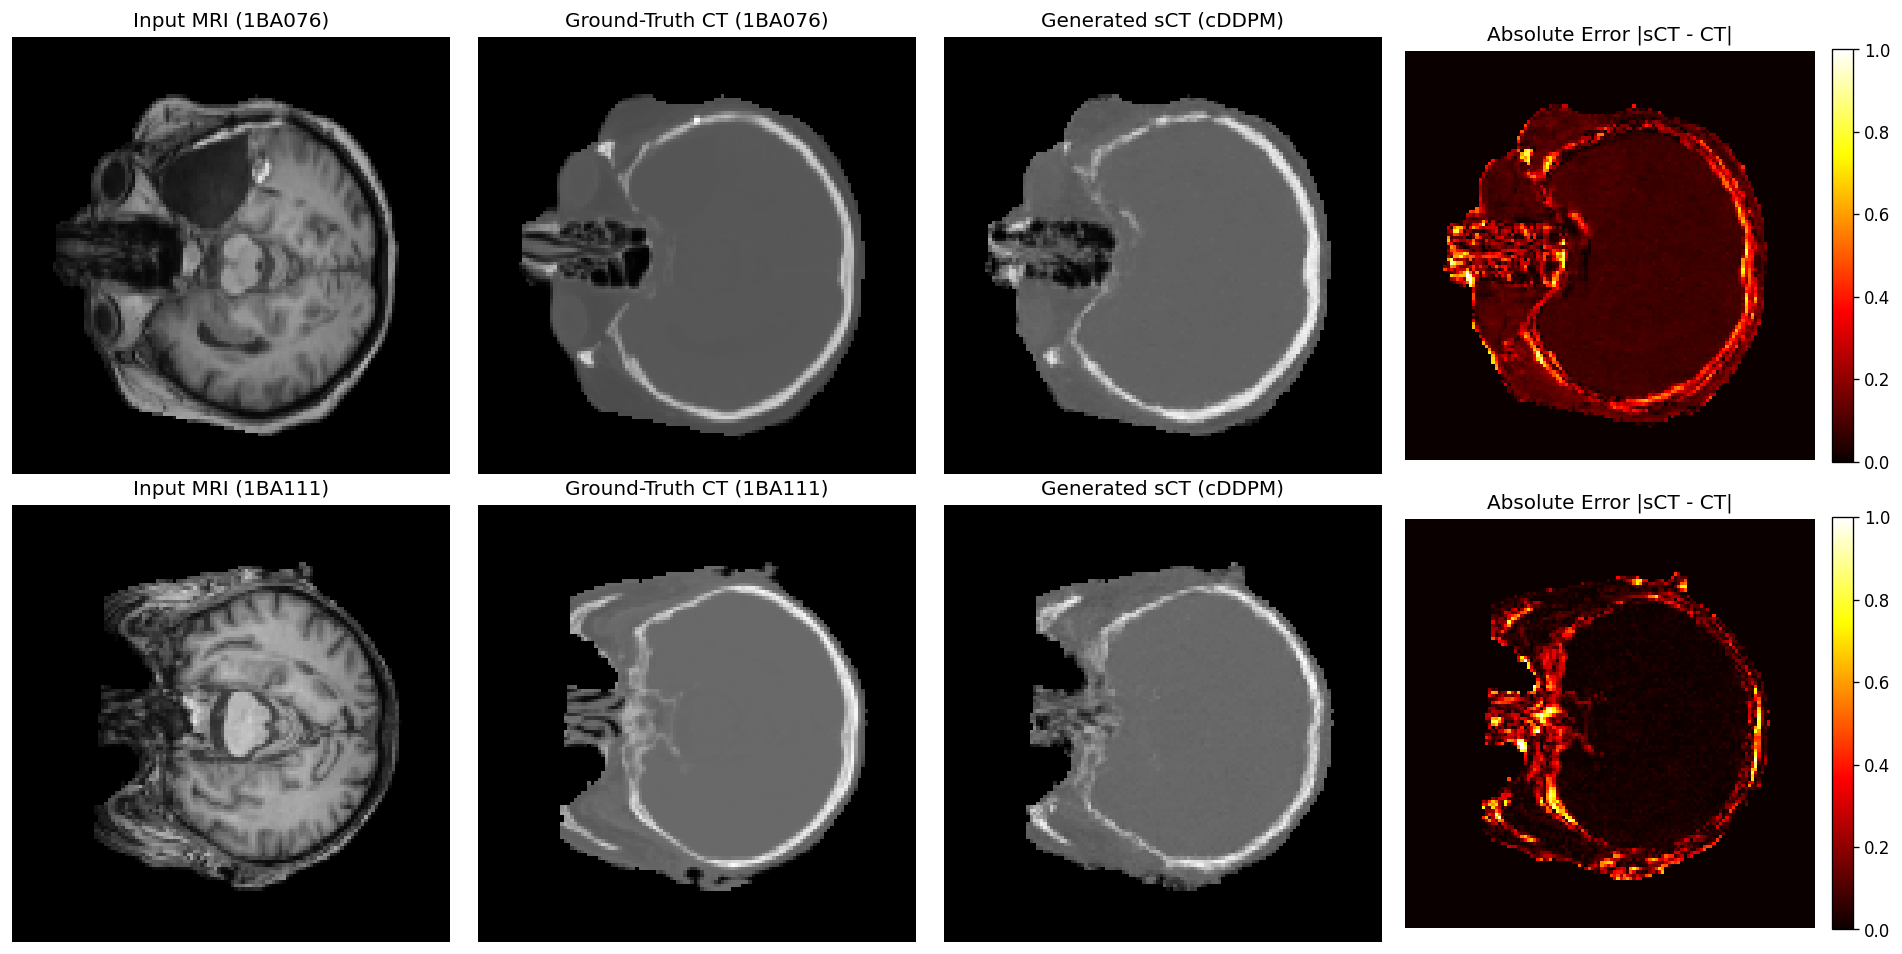

[OK] Scientific figures saved to: /kaggle/working/synthrad_model3_cddpm_from_scratch/figures


In [16]:
# =====================================================================
# CELL 14: SCIENTIFIC FIGURES & VISUALIZATION ARTIFACTS
# =====================================================================

# 1. Training and Validation Loss Curves
history_csv = os.path.join(DIR_METRICS, "validation_metrics_history.csv")
if os.path.exists(history_csv):
    df_h = pd.read_csv(history_csv)
    fig, ax1 = plt.subplots(figsize=(8, 4), dpi=120)
    ax1.plot(df_h["epoch"], df_h["train_mse_loss"], color="tab:blue", lw=2, label="Train MSE Loss")
    ax1.plot(df_h["epoch"], df_h["val_mse_loss"], color="tab:orange", lw=2, label="Val MSE Loss")
    ax1.set_xlabel("Epoch", fontsize=11)
    ax1.set_ylabel("Noise Prediction MSE Loss", fontsize=11)
    ax1.grid(True, alpha=0.3)
    ax1.legend(loc="upper right")
    plt.title("Model 3 (cDDPM From Scratch): Training and Validation Loss Curves", fontsize=12)
    plt.tight_layout()
    plt.savefig(os.path.join(DIR_FIGURES, "training_validation_loss_curves.png"))
    plt.show()

# 2. Qualitative 4-Panel Figure on Validation Patients
fig, axes = plt.subplots(2, 4, figsize=(16, 8), dpi=120)
val_pids_list = sorted(list(val_vis_dict.keys()))

for row_idx, pid in enumerate(val_pids_list[:2]):
    item = val_vis_dict[pid][len(val_vis_dict[pid]) // 2]
    mri_arr  = item["mri"]
    gt_arr   = item["gt"]
    sct_arr  = item["sct"]
    diff_arr = np.abs(sct_arr - gt_arr)

    axes[row_idx, 0].imshow(mri_arr, cmap="gray", vmin=-1.0, vmax=1.0)
    axes[row_idx, 0].set_title(f"Input MRI ({pid})")
    axes[row_idx, 0].axis("off")

    axes[row_idx, 1].imshow(gt_arr, cmap="gray", vmin=-1.0, vmax=1.0)
    axes[row_idx, 1].set_title(f"Ground-Truth CT ({pid})")
    axes[row_idx, 1].axis("off")

    axes[row_idx, 2].imshow(sct_arr, cmap="gray", vmin=-1.0, vmax=1.0)
    axes[row_idx, 2].set_title(f"Generated sCT (cDDPM)")
    axes[row_idx, 2].axis("off")

    im = axes[row_idx, 3].imshow(diff_arr, cmap="hot", vmin=0.0, vmax=1.0)
    axes[row_idx, 3].set_title(f"Absolute Error |sCT - CT|")
    axes[row_idx, 3].axis("off")
    fig.colorbar(im, ax=axes[row_idx, 3], fraction=0.046, pad=0.04)

plt.tight_layout()
plt.savefig(os.path.join(DIR_FIGURES, "qualitative_validation_4panel.png"))
plt.show()

print(f"[OK] Scientific figures saved to: {DIR_FIGURES}")


In [17]:
# =====================================================================
# CELL 15: RESEARCH SUMMARY REPORT & VERIFIED ZIP PACKAGING
# =====================================================================

# 1. Generate Research Summary Text Report
report_path = os.path.join(DIR_REPORTS, "experiment_summary.txt")
with open(report_path, "w", encoding="utf-8") as f:
    f.write("=" * 80 + "\n")
    f.write("SYNTHRAD2023 MODEL 3: CONDITIONAL DDPM FROM SCRATCH - EXPERIMENT REPORT\n")
    f.write("=" * 80 + "\n\n")
    f.write(f"Experiment Name        : {CONFIG['experiment_name']}\n")
    f.write(f"Output Directory       : {BASE_OUT_DIR}\n")
    f.write(f"Parameters Count       : {total_params:,}\n")
    f.write(f"Training Epochs        : {CONFIG['training']['epochs']}\n")
    f.write(f"Best Checkpoint Epoch  : {best_epoch}\n")
    f.write(f"Best Validation Score  : {best_val_score:.4f}\n\n")
    f.write("Dataset Partitions:\n")
    f.write(f"  - Training Set       : 48 patients (2,879 slices)\n")
    f.write(f"  - Validation Set     : 6 patients (372 slices)\n")
    f.write(f"  - Test Set (Frozen)  : 6 patients (363 slices)\n\n")
    f.write("Validation Results (Patient-Level Mean +/- Std):\n")
    if 'df_val_patients' in locals():
        f.write(f"  - Masked MAE (norm)  : {df_val_patients['Masked_MAE_norm_mean'].mean():.4f} +/- {df_val_patients['Masked_MAE_norm_mean'].std():.4f}\n")
        f.write(f"  - Masked SSIM        : {df_val_patients['Masked_SSIM_mean'].mean():.4f} +/- {df_val_patients['Masked_SSIM_mean'].std():.4f}\n")
        f.write(f"  - Masked PSNR (dB)   : {df_val_patients['Masked_PSNR_dB_mean'].mean():.2f} +/- {df_val_patients['Masked_PSNR_dB_mean'].std():.2f}\n")
    f.write("\nLimitations & Protocol Notes:\n")
    f.write("  1. Custom 60-patient 2D PNG split, not the official 3D SynthRAD challenge split.\n")
    f.write("  2. PNG-to-HU intensity mapping is uncalibrated and provisional.\n")
    f.write("  3. Test set was strictly frozen during training and model selection.\n")
    f.write("=" * 80 + "\n")

print(f"[OK] Experiment summary report generated: {report_path}")

# 2. Verified Deliverables ZIP Packaging
zip_dest = os.path.join(os.path.dirname(BASE_OUT_DIR), "synthrad_model3_cddpm_from_scratch_deliverables.zip")
if not os.path.exists(os.path.dirname(BASE_OUT_DIR)):
    zip_dest = "synthrad_model3_cddpm_from_scratch_deliverables.zip"

print(f"Creating deliverables archive: {zip_dest}")
with zipfile.ZipFile(zip_dest, "w", zipfile.ZIP_DEFLATED) as zipf:
    for root, dirs, files in os.walk(BASE_OUT_DIR):
        for file in sorted(files):
            file_path = os.path.join(root, file)
            arcname = os.path.relpath(file_path, BASE_OUT_DIR)
            zipf.write(file_path, arcname)

archive_size_mb = os.path.getsize(zip_dest) / (1024 ** 2)
print(f"[OK] Deliverables ZIP archive verified: {zip_dest} ({archive_size_mb:.2f} MB)")

with zipfile.ZipFile(zip_dest, "r") as z:
    archived_files = z.namelist()

print(f"Total verified archived members: {len(archived_files)}")
for item in sorted(archived_files):
    if item.endswith(".pth") or item.endswith(".json") or item.endswith(".csv") or item.endswith(".png"):
        print(f"  - {item}")

print("=" * 80)
print("MODEL 3 FROM-SCRATCH PIPELINE FULLY COMPLETED AND ARCHIVED.")
print("=" * 80)


[OK] Experiment summary report generated: /kaggle/working/synthrad_model3_cddpm_from_scratch/reports/experiment_summary.txt
Creating deliverables archive: /kaggle/working/synthrad_model3_cddpm_from_scratch_deliverables.zip
[OK] Deliverables ZIP archive verified: /kaggle/working/synthrad_model3_cddpm_from_scratch_deliverables.zip (651.90 MB)
Total verified archived members: 29
  - checkpoints/best_model3_cddpm_from_scratch.pth
  - checkpoints/checkpoint_epoch_005.pth
  - checkpoints/checkpoint_epoch_010.pth
  - checkpoints/checkpoint_epoch_015.pth
  - checkpoints/checkpoint_epoch_020.pth
  - checkpoints/checkpoint_epoch_025.pth
  - checkpoints/checkpoint_epoch_030.pth
  - checkpoints/checkpoint_epoch_035.pth
  - checkpoints/checkpoint_epoch_040.pth
  - checkpoints/checkpoint_epoch_045.pth
  - checkpoints/checkpoint_epoch_050.pth
  - checkpoints/checkpoint_epoch_055.pth
  - checkpoints/checkpoint_epoch_060.pth
  - checkpoints/checkpoint_epoch_065.pth
  - checkpoints/checkpoint_epoch_070.

In [18]:
# =====================================================================
# CELL 16: OPTIONAL FROZEN TEST EVALUATION (STRICTLY GATED & DISABLED)
# =====================================================================

# SAFETY GUARD: Kept strictly False by default.
# Only set to True after training is complete and the final checkpoint is selected.
ENABLE_FROZEN_TEST_EVAL = False

print("=" * 80)
print("CELL 16: FROZEN TEST SET EVALUATION (HELD-OUT 6 PATIENTS, 363 SLICES)")
print(f"ENABLE_FROZEN_TEST_EVAL status: {ENABLE_FROZEN_TEST_EVAL}")
print("=" * 80)

if not ENABLE_FROZEN_TEST_EVAL:
    print("--> Held-out test evaluation is DISABLED.")
    print("    This prevents data leakage and preserves test set isolation during research.")
    print("    To evaluate the frozen best checkpoint on the test cohort, explicitly set:")
    print("    ENABLE_FROZEN_TEST_EVAL = True and run this cell manually.")
else:
    print("Running evaluation on FROZEN HELD-OUT TEST COHORT (6 patients: 1BA054, 1BA097, 1BA172, 1BA234, 1BA256, 1BA307)...")
    test_eval_loader = DataLoader(test_dataset_eval, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
    df_test_slices, df_test_patients, test_vis_dict = evaluate_full_split(test_eval_loader, "Test")

    df_test_slices.to_csv(os.path.join(DIR_METRICS, "test_slice_metrics.csv"), index=False)
    df_test_patients.to_csv(os.path.join(DIR_METRICS, "test_patient_metrics.csv"), index=False)

    print("\n" + "=" * 80)
    print("FINAL HELD-OUT TEST EVALUATION RESULTS (PATIENT-LEVEL MEAN +/- STD):")
    print("=" * 80)
    print(f"  Test Masked MAE (norm)         : {df_test_patients['Masked_MAE_norm_mean'].mean():.4f} +/- {df_test_patients['Masked_MAE_norm_mean'].std():.4f}")
    print(f"  Test Masked SSIM               : {df_test_patients['Masked_SSIM_mean'].mean():.4f} +/- {df_test_patients['Masked_SSIM_mean'].std():.4f}")
    print(f"  Test Masked PSNR (dB)          : {df_test_patients['Masked_PSNR_dB_mean'].mean():.2f} +/- {df_test_patients['Masked_PSNR_dB_mean'].std():.2f}")
    print(f"  Test Global SSIM               : {df_test_patients['SSIM_mean'].mean():.4f} +/- {df_test_patients['SSIM_mean'].std():.4f}")
    print(f"  Test Provisional Masked HU-MAE : {df_test_patients['Provisional_Masked_HU_MAE_mean'].mean():.1f} +/- {df_test_patients['Provisional_Masked_HU_MAE_mean'].std():.1f} HU")
    print("=" * 80)


CELL 16: FROZEN TEST SET EVALUATION (HELD-OUT 6 PATIENTS, 363 SLICES)
ENABLE_FROZEN_TEST_EVAL status: False
--> Held-out test evaluation is DISABLED.
    This prevents data leakage and preserves test set isolation during research.
    To evaluate the frozen best checkpoint on the test cohort, explicitly set:
    ENABLE_FROZEN_TEST_EVAL = True and run this cell manually.


FROZEN MODEL 3 EVALUATION
Checkpoint : /kaggle/working/synthrad_model3_cddpm_from_scratch/checkpoints/best_model3_cddpm_from_scratch.pth
Best epoch : 60
Best score : 0.07545658490033587
DDIM steps : 50

[PASS] Exact patient IDs verified.
Train       : 48 patients, 2879 slices
Validation  : 6 patients, 372 slices
Test        : 6 patients, 363 slices

STARTING FROZEN TRAIN EVALUATION


Evaluating Train:   0%|          | 0/360 [00:00<?, ?it/s]

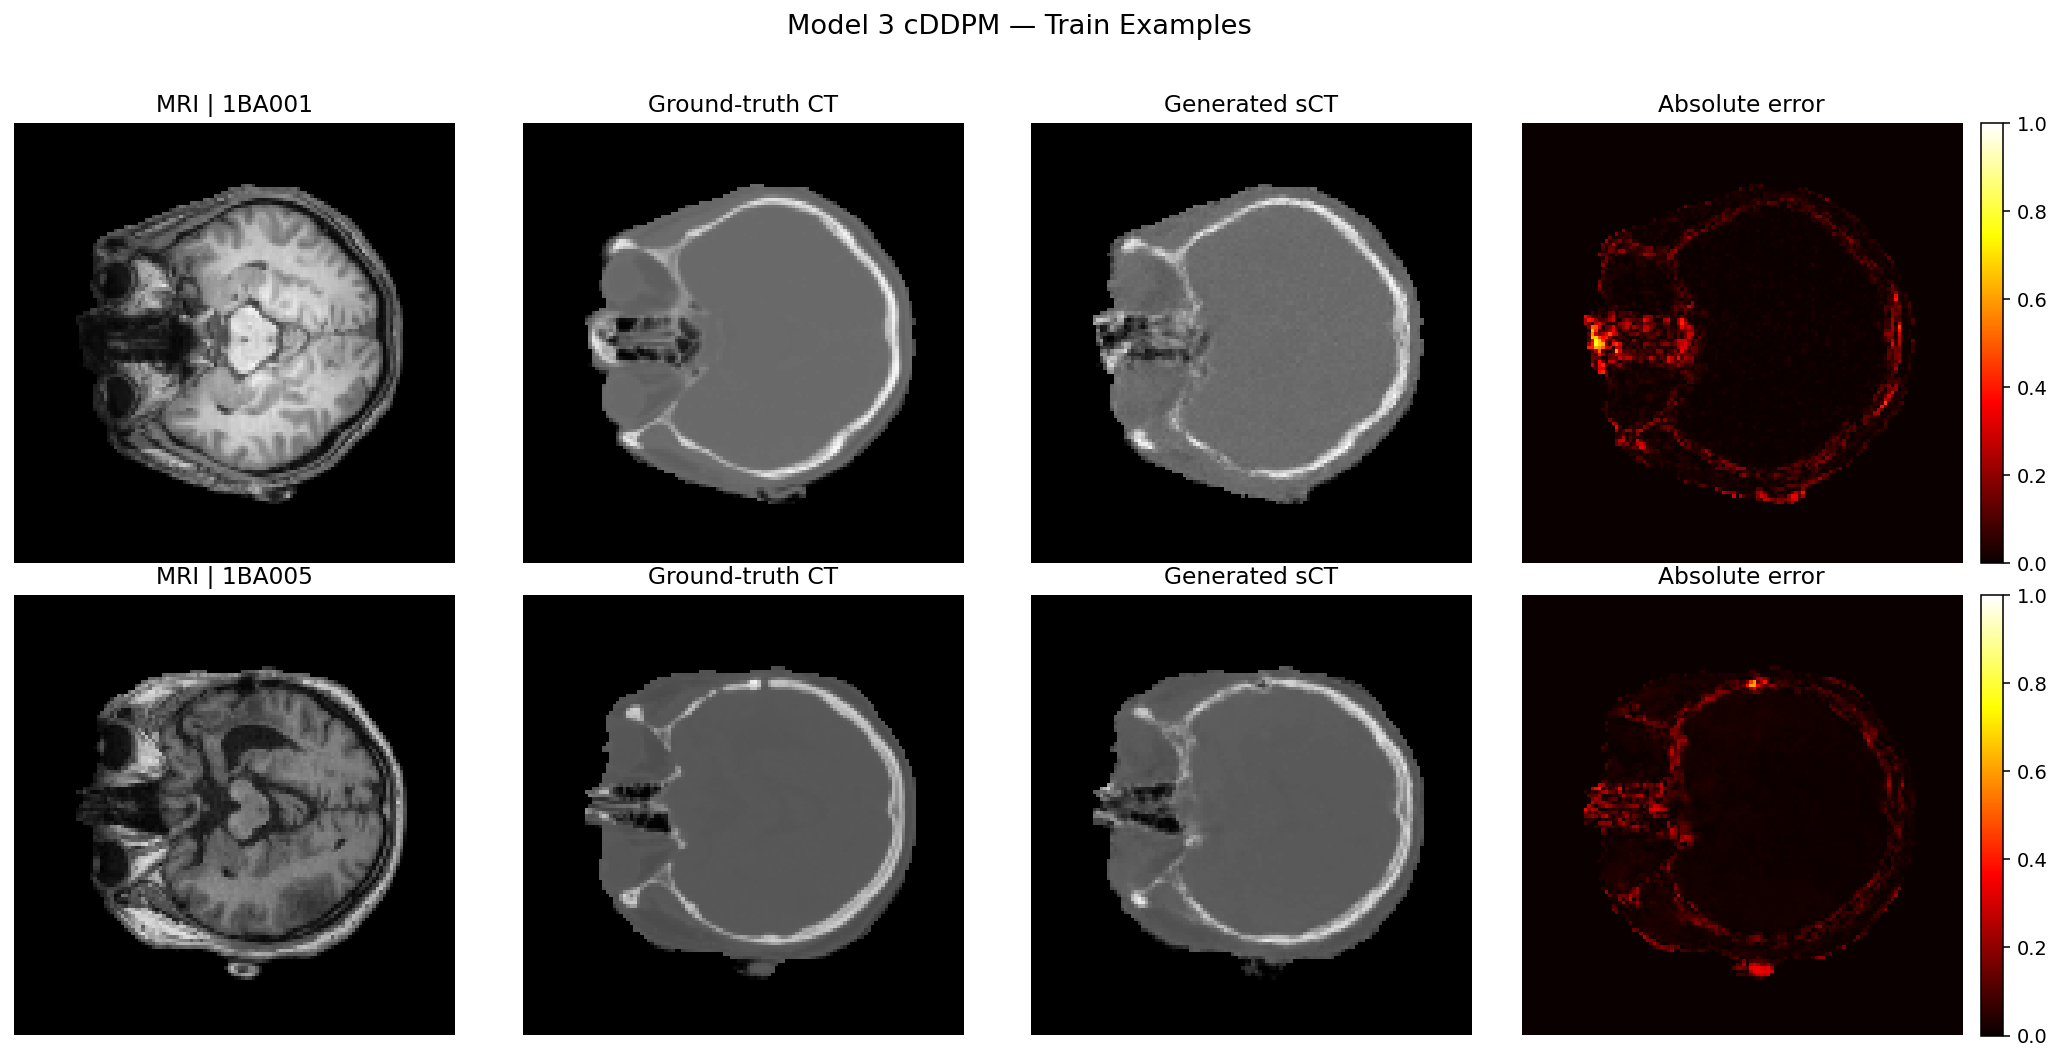

[SAVED] /kaggle/working/synthrad_model3_cddpm_from_scratch/figures/train_qualitative_evaluation.png

TRAIN — PATIENT-LEVEL MEAN ± SD
------------------------------------------------------------
Masked_MAE_norm                 : 0.0500 ± 0.0044
Masked_SSIM                     : 0.8493 ± 0.0265
Masked_PSNR_dB                  : 22.17 ± 0.71
SSIM                            : 0.9206 ± 0.0131
Provisional_Masked_HU_MAE       : 125.0 ± 11.0 (PROVISIONAL HU)

STARTING FROZEN VALIDATION EVALUATION


Evaluating Validation:   0%|          | 0/47 [00:00<?, ?it/s]

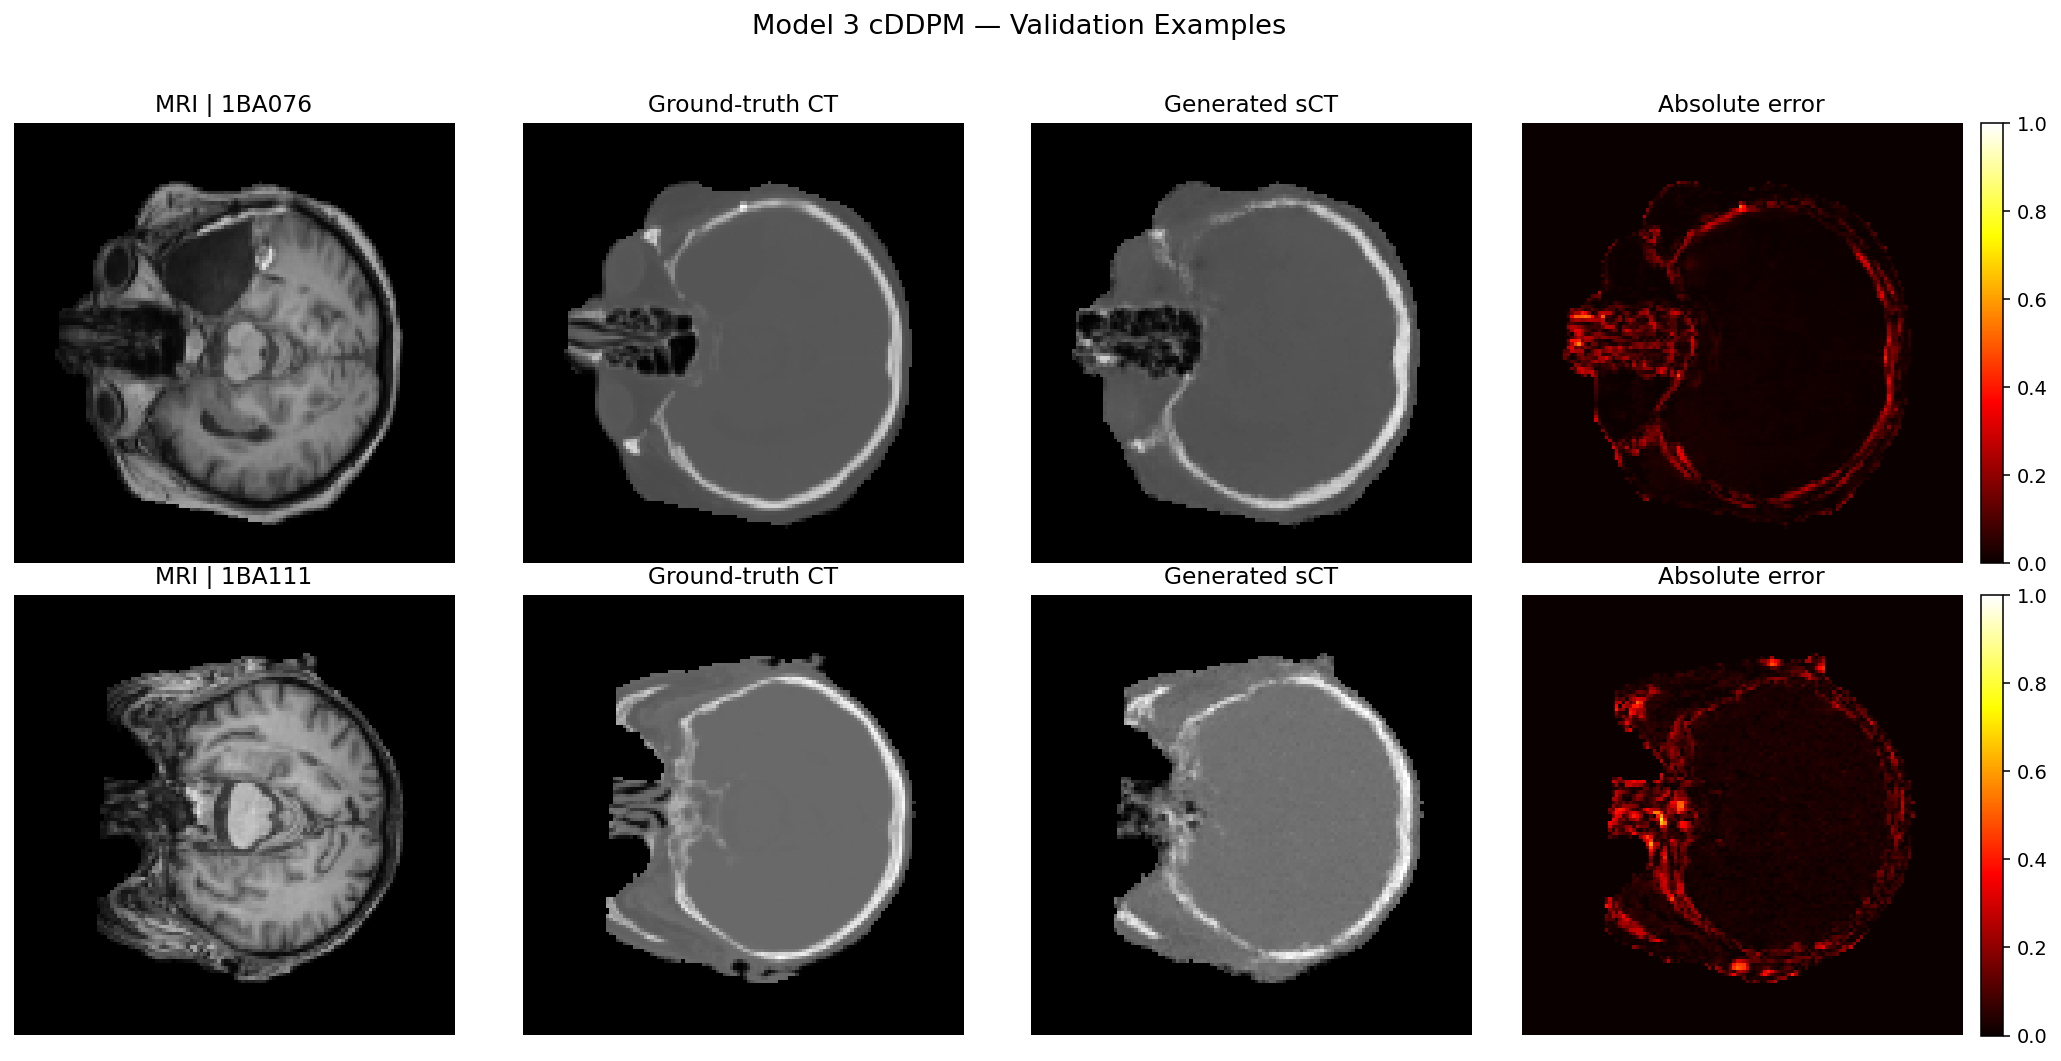

[SAVED] /kaggle/working/synthrad_model3_cddpm_from_scratch/figures/validation_qualitative_evaluation.png

VALIDATION — PATIENT-LEVEL MEAN ± SD
------------------------------------------------------------
Masked_MAE_norm                 : 0.0575 ± 0.0067
Masked_SSIM                     : 0.8204 ± 0.0229
Masked_PSNR_dB                  : 21.15 ± 0.57
SSIM                            : 0.9050 ± 0.0078
Provisional_Masked_HU_MAE       : 143.7 ± 16.8 (PROVISIONAL HU)

STARTING FROZEN TEST EVALUATION


Evaluating Test:   0%|          | 0/46 [00:00<?, ?it/s]

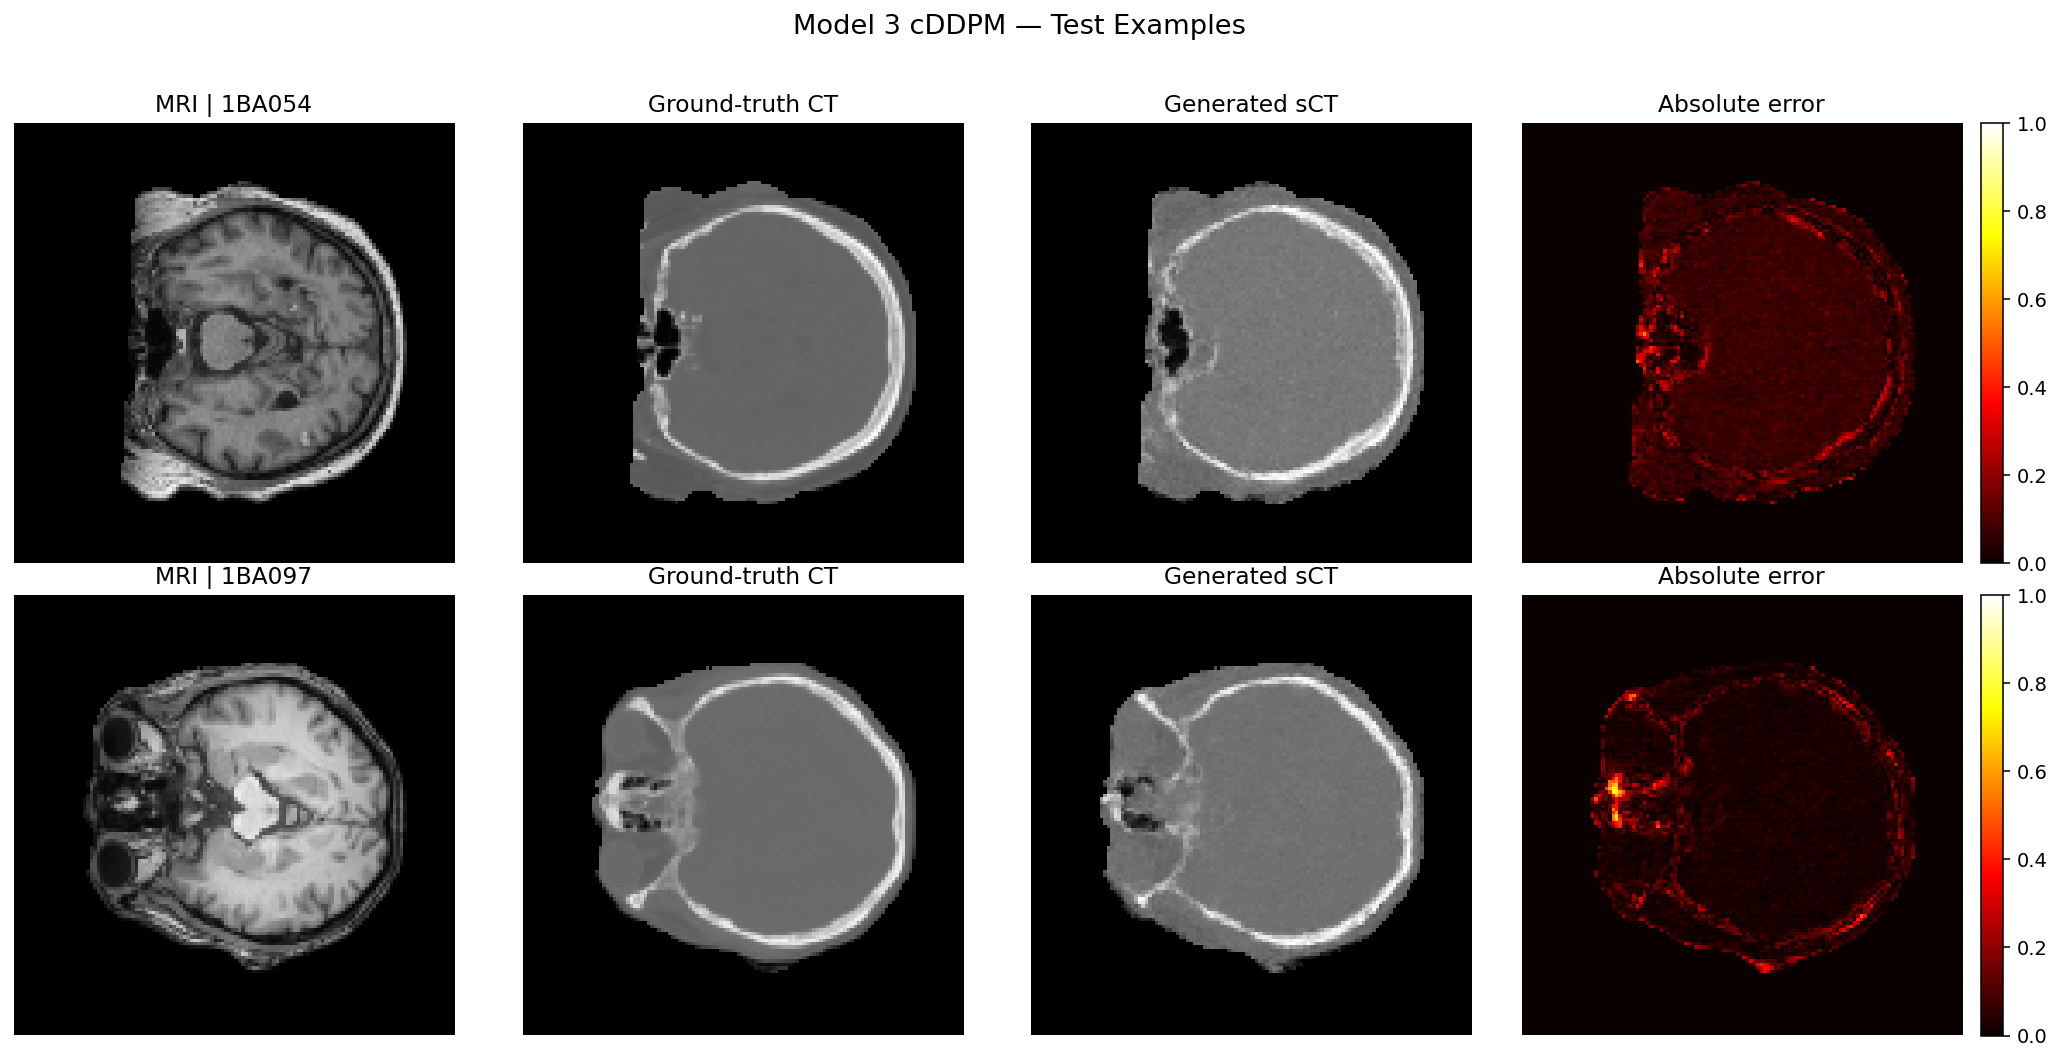

[SAVED] /kaggle/working/synthrad_model3_cddpm_from_scratch/figures/test_qualitative_evaluation.png

TEST — PATIENT-LEVEL MEAN ± SD
------------------------------------------------------------
Masked_MAE_norm                 : 0.0536 ± 0.0044
Masked_SSIM                     : 0.8391 ± 0.0246
Masked_PSNR_dB                  : 21.63 ± 0.61
SSIM                            : 0.9166 ± 0.0085
Provisional_Masked_HU_MAE       : 134.1 ± 11.1 (PROVISIONAL HU)

ALL-SPLIT EVALUATION COMPLETED
     split  patients  slices  Masked_MAE_norm_patient_mean  Masked_MAE_norm_patient_std  Masked_SSIM_patient_mean  Masked_SSIM_patient_std  Masked_PSNR_dB_patient_mean  Masked_PSNR_dB_patient_std  SSIM_patient_mean  SSIM_patient_std  Provisional_Masked_HU_MAE_patient_mean  Provisional_Masked_HU_MAE_patient_std
     Train        48    2879                      0.050013                     0.004381                  0.849346                 0.026522                    22.170654                    0.714841        

In [19]:

# =====================================================================
# MODEL 3 — FROZEN EVALUATION: TRAIN + VALIDATION + TEST
# Run after training has finished and best checkpoint is selected.
#
# Uses existing notebook objects:
# model3, scheduler, device, CONFIG,
# train_eval_loader, val_loader, test_dataset_eval,
# evaluate_slice, EXPECTED_TRAIN_PIDS, EXPECTED_VAL_PIDS,
# EXPECTED_TEST_PIDS, FIXED_VAL_NOISE, DIR_CHECKPOINTS,
# DIR_METRICS, DIR_FIGURES
# =====================================================================

import os
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from pathlib import Path
from torch.utils.data import DataLoader
from tqdm.auto import tqdm

# ---------------------------------------------------------------------
# 1. Configuration and output folders
# ---------------------------------------------------------------------

BEST_CKPT = os.path.join(
    DIR_CHECKPOINTS,
    "best_model3_cddpm_from_scratch.pth"
)

DDIM_STEPS = CONFIG["diffusion"]["ddim_inference_steps"]
IMG_SIZE = CONFIG["dataset"]["image_size"]
BATCH_SIZE_EVAL = CONFIG["training"]["batch_size"]

Path(DIR_METRICS).mkdir(parents=True, exist_ok=True)
Path(DIR_FIGURES).mkdir(parents=True, exist_ok=True)

if not os.path.isfile(BEST_CKPT):
    raise FileNotFoundError(f"Best checkpoint not found: {BEST_CKPT}")

# ---------------------------------------------------------------------
# 2. Load and freeze the selected checkpoint
# ---------------------------------------------------------------------

checkpoint = torch.load(BEST_CKPT, map_location=device)
model3.load_state_dict(checkpoint["model_state_dict"], strict=True)
model3.eval()

for parameter in model3.parameters():
    parameter.requires_grad_(False)

print("=" * 80)
print("FROZEN MODEL 3 EVALUATION")
print(f"Checkpoint : {BEST_CKPT}")
print(f"Best epoch : {checkpoint.get('epoch', 'unknown')}")
print(f"Best score : {checkpoint.get('val_score', 'unknown')}")
print(f"DDIM steps : {DDIM_STEPS}")
print("=" * 80)

# ---------------------------------------------------------------------
# 3. Construct split loaders
#
# IMPORTANT: train_eval_loader must be unaugmented.
# Do not evaluate training performance using augmented train_loader.
# ---------------------------------------------------------------------

test_eval_loader = DataLoader(
    test_dataset_eval,
    batch_size=BATCH_SIZE_EVAL,
    shuffle=False,
    num_workers=0,
    pin_memory=(device.type == "cuda")
)

split_loaders = {
    "Train": train_eval_loader,
    "Validation": val_loader,
    "Test": test_eval_loader,
}

expected_patient_ids = {
    "Train": set(EXPECTED_TRAIN_PIDS),
    "Validation": set(EXPECTED_VAL_PIDS),
    "Test": set(EXPECTED_TEST_PIDS),
}

# Verify the actual patient IDs in each dataset.
for split_name, loader in split_loaders.items():
    dataset = loader.dataset

    if not hasattr(dataset, "mri_paths"):
        raise AttributeError(
            f"{split_name} dataset has no mri_paths attribute."
        )

    actual_ids = {
        Path(path).name.split("_")[0]
        for path in dataset.mri_paths
    }

    if actual_ids != expected_patient_ids[split_name]:
        raise AssertionError(
            f"{split_name} patient split mismatch.\n"
            f"Missing: {sorted(expected_patient_ids[split_name] - actual_ids)}\n"
            f"Unexpected: {sorted(actual_ids - expected_patient_ids[split_name])}"
        )

# Confirm all three partitions are independent.
assert expected_patient_ids["Train"].isdisjoint(
    expected_patient_ids["Validation"]
)
assert expected_patient_ids["Train"].isdisjoint(
    expected_patient_ids["Test"]
)
assert expected_patient_ids["Validation"].isdisjoint(
    expected_patient_ids["Test"]
)

print("\n[PASS] Exact patient IDs verified.")
for split_name, loader in split_loaders.items():
    print(
        f"{split_name:12s}: "
        f"{len(expected_patient_ids[split_name])} patients, "
        f"{len(loader.dataset)} slices"
    )

# ---------------------------------------------------------------------
# 4. Deterministic initial noise
#
# The DDIM sampler accepts initial_noise. We use:
# - The same FIXED_VAL_NOISE pool used in checkpoint selection for val.
# - A reproducible, distinct initial noise for each train/test slice.
# ---------------------------------------------------------------------

EVAL_NOISE_SEED = 20261009

def deterministic_noise_for_slice(split_name, slice_name):
    token = f"{EVAL_NOISE_SEED}:{split_name}:{slice_name}".encode("utf-8")
    seed = int(hashlib.sha256(token).hexdigest()[:8], 16)

    generator = torch.Generator(device="cpu")
    generator.manual_seed(seed)

    return torch.randn(
        (1, 1, IMG_SIZE, IMG_SIZE),
        generator=generator,
        dtype=torch.float32
    )

def get_midpoint_slice_names(dataset, max_patients=2):
    """Choose the middle filename of up to two patients for visualization."""
    patient_files = {}

    for path in dataset.mri_paths:
        name = Path(path).name
        pid = name.split("_")[0]
        patient_files.setdefault(pid, []).append(name)

    selected = set()

    for pid in sorted(patient_files)[:max_patients]:
        names = sorted(patient_files[pid])
        selected.add(names[len(names) // 2])

    return selected

# These metric keys are returned by the existing evaluate_slice().
METRIC_COLUMNS = [
    "MAE_norm",
    "Masked_MAE_norm",
    "PSNR_dB",
    "Masked_PSNR_dB",
    "SSIM",
    "Masked_SSIM",
    "Provisional_HU_MAE",
    "Provisional_Masked_HU_MAE",
    "Provisional_Bone_Dice",
]

# ---------------------------------------------------------------------
# 5. Evaluate one split and retain only selected images in memory
# ---------------------------------------------------------------------

def evaluate_frozen_split(loader, split_name):
    model3.eval()

    slice_records = []
    visual_examples = []

    dataset = loader.dataset
    selected_names = get_midpoint_slice_names(
        dataset, max_patients=2
    )

    global_index = 0

    use_fixed_validation_noise = (
        split_name == "Validation"
        and "FIXED_VAL_NOISE" in globals()
        and len(FIXED_VAL_NOISE) == len(dataset)
    )

    with torch.inference_mode():
        for batch in tqdm(
            loader,
            desc=f"Evaluating {split_name}"
        ):
            mri = batch["mri"].to(device, non_blocking=True)
            ct = batch["ct"].to(device, non_blocking=True)
            mask = batch["mask"].to(device, non_blocking=True)

            patient_ids = [str(x) for x in batch["patient_id"]]
            slice_names = [str(x) for x in batch["slice_name"]]
            batch_size = mri.shape[0]

            # Use the exact deterministic noise pool from validation
            # checkpoint selection when it is available.
            if use_fixed_validation_noise:
                initial_noise = torch.cat([
                    FIXED_VAL_NOISE[global_index + i]
                    for i in range(batch_size)
                ], dim=0).to(device)
            else:
                initial_noise = torch.cat([
                    deterministic_noise_for_slice(
                        split_name, slice_names[i]
                    )
                    for i in range(batch_size)
                ], dim=0).to(device)

            global_index += batch_size

            sct = scheduler.sample_ddim(
                model3,
                mri,
                mask,
                ddim_steps=DDIM_STEPS,
                initial_noise=initial_noise
            )

            mri_np = mri[:, 0].float().cpu().numpy()
            ct_np = ct[:, 0].float().cpu().numpy()
            mask_np = mask[:, 0].float().cpu().numpy()
            sct_np = sct[:, 0].float().cpu().numpy()

            for i in range(batch_size):
                pid = patient_ids[i]
                sname = slice_names[i]

                metrics = evaluate_slice(
                    sct_np[i],
                    ct_np[i],
                    mask_np[i]
                )

                record = {
                    "split": split_name,
                    "patient_id": pid,
                    "slice_name": sname,
                    **metrics
                }
                slice_records.append(record)

                # Store only selected representative examples.
                if sname in selected_names:
                    visual_examples.append({
                        "patient_id": pid,
                        "slice_name": sname,
                        "mri": mri_np[i],
                        "ct": ct_np[i],
                        "sct": sct_np[i],
                        "mask": mask_np[i],
                        "metrics": metrics
                    })

    df_slices = pd.DataFrame(slice_records)

    if df_slices.empty:
        raise RuntimeError(f"No slices evaluated for {split_name}.")

    # Patient-level means: first summarize slices within each patient.
    patient_records = []

    for pid, group in df_slices.groupby("patient_id", sort=True):
        patient_row = {
            "split": split_name,
            "patient_id": pid,
            "slice_count": len(group)
        }

        for metric in METRIC_COLUMNS:
            patient_row[f"{metric}_mean"] = group[metric].mean()
            patient_row[f"{metric}_std"] = group[metric].std(ddof=1)

        patient_records.append(patient_row)

    df_patients = pd.DataFrame(patient_records)

    # Save detailed metrics for the split.
    df_slices.to_csv(
        os.path.join(
            DIR_METRICS,
            f"{split_name.lower()}_slice_metrics.csv"
        ),
        index=False
    )

    df_patients.to_csv(
        os.path.join(
            DIR_METRICS,
            f"{split_name.lower()}_patient_metrics.csv"
        ),
        index=False
    )

    return df_slices, df_patients, visual_examples

# ---------------------------------------------------------------------
# 6. Visualize MRI, reference CT, generated CT and absolute error
# ---------------------------------------------------------------------

def save_qualitative_figure(visual_examples, split_name):
    if not visual_examples:
        print(f"[WARNING] No selected visual examples for {split_name}.")
        return

    n = len(visual_examples)
    fig, axes = plt.subplots(
        n, 4,
        figsize=(15, 3.8 * n),
        squeeze=False,
        dpi=140
    )

    for row, item in enumerate(visual_examples):
        mri = item["mri"]
        ct = item["ct"]
        sct = item["sct"]

        # Convert both images from [-1, 1] to [0, 1] before calculating
        # the displayed absolute error.
        error = np.abs((sct + 1.0) / 2.0 - (ct + 1.0) / 2.0)

        axes[row, 0].imshow(mri, cmap="gray", vmin=-1, vmax=1)
        axes[row, 0].set_title(
            f"MRI | {item['patient_id']}"
        )

        axes[row, 1].imshow(ct, cmap="gray", vmin=-1, vmax=1)
        axes[row, 1].set_title("Ground-truth CT")

        axes[row, 2].imshow(sct, cmap="gray", vmin=-1, vmax=1)
        axes[row, 2].set_title("Generated sCT")

        im = axes[row, 3].imshow(
            error, cmap="hot", vmin=0, vmax=1
        )
        axes[row, 3].set_title("Absolute error")

        for ax in axes[row]:
            ax.axis("off")

        fig.colorbar(
            im, ax=axes[row, 3],
            fraction=0.046, pad=0.04
        )

    fig.suptitle(
        f"Model 3 cDDPM — {split_name} Examples",
        fontsize=14
    )
    plt.tight_layout(rect=[0, 0, 1, 0.96])

    out_path = os.path.join(
        DIR_FIGURES,
        f"{split_name.lower()}_qualitative_evaluation.png"
    )
    fig.savefig(out_path, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    print(f"[SAVED] {out_path}")

# ---------------------------------------------------------------------
# 7. Run evaluation on all splits
#
# Test evaluation here is appropriate only because the checkpoint
# has already been selected using validation, not test performance.
# Do not tune/reselect the model based on test results.
# ---------------------------------------------------------------------

all_slice_tables = []
all_patient_tables = []
summary_rows = []

for split_name, loader in split_loaders.items():
    print("\n" + "=" * 80)
    print(f"STARTING FROZEN {split_name.upper()} EVALUATION")
    print("=" * 80)

    df_slices, df_patients, examples = evaluate_frozen_split(
        loader, split_name
    )

    all_slice_tables.append(df_slices)
    all_patient_tables.append(df_patients)

    save_qualitative_figure(examples, split_name)

    # Report average and SD across patient-level means (not pooled slices).
    summary = {
        "split": split_name,
        "patients": df_patients["patient_id"].nunique(),
        "slices": len(df_slices)
    }

    primary_metrics = [
        "Masked_MAE_norm",
        "Masked_SSIM",
        "Masked_PSNR_dB",
        "SSIM",
        "Provisional_Masked_HU_MAE"
    ]

    print(f"\n{split_name.upper()} — PATIENT-LEVEL MEAN ± SD")
    print("-" * 60)

    for metric in primary_metrics:
        col = f"{metric}_mean"
        mean_value = df_patients[col].mean()
        std_value = df_patients[col].std(ddof=1)

        summary[f"{metric}_patient_mean"] = mean_value
        summary[f"{metric}_patient_std"] = std_value

        if "PSNR" in metric:
            print(
                f"{metric:32s}: "
                f"{mean_value:.2f} ± {std_value:.2f}"
            )
        elif "HU_MAE" in metric:
            print(
                f"{metric:32s}: "
                f"{mean_value:.1f} ± {std_value:.1f} "
                f"(PROVISIONAL HU)"
            )
        else:
            print(
                f"{metric:32s}: "
                f"{mean_value:.4f} ± {std_value:.4f}"
            )

    summary_rows.append(summary)

# ---------------------------------------------------------------------
# 8. Export a combined report for easy comparison
# ---------------------------------------------------------------------

df_all_slices = pd.concat(all_slice_tables, ignore_index=True)
df_all_patients = pd.concat(all_patient_tables, ignore_index=True)
df_summary = pd.DataFrame(summary_rows)

df_all_slices.to_csv(
    os.path.join(DIR_METRICS, "all_splits_slice_metrics.csv"),
    index=False
)
df_all_patients.to_csv(
    os.path.join(DIR_METRICS, "all_splits_patient_metrics.csv"),
    index=False
)
df_summary.to_csv(
    os.path.join(DIR_METRICS, "all_splits_summary.csv"),
    index=False
)

print("\n" + "=" * 80)
print("ALL-SPLIT EVALUATION COMPLETED")
print("=" * 80)
print(df_summary.to_string(index=False))
print(f"\nCSV output directory : {DIR_METRICS}")
print(f"Figure output folder : {DIR_FIGURES}")
